In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import IterableDataset, DataLoader
import cudf
import cupy as cp
import numpy as np
import os
import fsspec
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score
import dask_cudf
from dask.distributed import Client, progress
from dask_cuda import LocalCUDACluster
from torch.cuda.amp import autocast, GradScaler
import dask.dataframe as dd
import dask.array as da
from torch.utils.data import DataLoader, Dataset
import pandas as pd
import pyarrow.parquet as pq
import torch.optim as optim
import ast
import torch.nn.functional as F
import dask.dataframe as dd
from tqdm.auto import tqdm # For progress bar


In [2]:
#torch.set_float32_matmul_precision('high')
#torch.backends.cuda.matmul.fp32_precision = 'ieee'


# 1. New API for TF32 control (removes the deprecation warning)
torch.backends.cuda.matmul.fp32_precision = 'tf32' 

# 2. Enables high precision (TF32) for better Inductor/GPU performance 
# (removes the performance warning)
torch.set_float32_matmul_precision('high')



/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/torch/__init__.py:1624: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  _C._set_float32_matmul_precision(precision)


In [3]:
#import dask
#import dask_cuda
#import cudf
#import cupy
#from dask.distributed import Client, LocalCluster
#from dask_cuda import LocalCUDACluster
#import dask_cudf
#import os

# --- Configuration for Resource Usage ---
# Get total memory from nvidia-smi output (49140 MiB for RTX A6000)
# Convert MiB to Bytes: 49140 * 1024 * 1024 = 51520630784 Bytes
TOTAL_GPU_MEMORY_BYTES = 97887 * 1024 * 1024 

# Desired usage percentage
GPU_MEMORY_PERCENTAGE_TO_USE = 0.70 # 70%

# Calculate the memory limit for each worker
# LocalCUDACluster by default launches one worker per available GPU.
# So, if you have one A6000, one worker will use 70% of its memory.
DEVICE_MEMORY_LIMIT = int(TOTAL_GPU_MEMORY_BYTES * GPU_MEMORY_PERCENTAGE_TO_USE)

# You can optionally specify which GPUs to use if you have multiple
# and want to restrict to certain ones.
# For a single A6000, this is often not necessary unless you have other processes.
# CUDA_VISIBLE_DEVICES = "0" # Use only GPU 0

# --- Dask Cluster Setup ---
print(f"Setting device_memory_limit per worker to: {DEVICE_MEMORY_LIMIT / (1024**3):.2f} GB ({GPU_MEMORY_PERCENTAGE_TO_USE*100:.0f}% of total GPU memory)")

# 1. Start a Local Dask Cluster with GPU resources
# We pass the calculated device_memory_limit here.
# n_workers can be specified if you have multiple GPUs and want to use a subset.
# threads_per_worker is generally 1 for Dask-CUDA with cuDF/CuPy for best performance
# due to how CUDA streams and contexts are managed, especially if using RMM pools.
cluster = LocalCUDACluster(
    device_memory_limit=DEVICE_MEMORY_LIMIT,
    # Crucial for large workloads and preventing OOM:
    enable_cudf_spill=True, # Enable cuDF's native spilling to host if GPU memory is exhausted

    # Optional UCX for performance (requires ucx-py installed)
    protocol="ucx",
    enable_tcp_over_ucx=True,

    # threads_per_worker is generally 1 for CUDA workloads with cuDF/CuPy
    threads_per_worker=1,
)
client = Client(cluster)

print("\nDask Dashboard Link:", client.dashboard_link)
print("------------------------------------------")
print("Dask Client Info:")
print(client)
print("------------------------------------------")


Setting device_memory_limit per worker to: 66.91 GB (70% of total GPU memory)


/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/rapids_dask_dependency/patches/distributed/comm/__rdd_patch_ucx.py:572: FutureWarning: you have requested protocol='ucx', which now defaults to UCXX but
the package 'distributed-ucxx' is not installed. The current version
of Distributed will fallback to using UCX-Py, but this fallback is
deprecated and will be removed in the next release (RAPIDS 25.10).
To silence this warning and use UCXX, install the 'distributed-ucxx'
package, or to use UCX-Py and silence the warning, use
'protocol="ucx-old"' when you create your Distributed or Dask-CUDA
cluster.                
  warnings.warn(
/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/rapids_dask_dependency/patches/distributed/comm/__rdd_patch_ucx.py:572: FutureWarning: you have requested protocol='ucx', which now defaults to UCXX but
the package 'distributed-ucxx' is not installed. The current version
of Distributed will fallback to using UCX-Py, but this 


Dask Dashboard Link: http://127.0.0.1:8787/status
------------------------------------------
Dask Client Info:
<Client: 'ucx://127.0.0.1:34159' processes=1 threads=1, memory=0.98 TiB>
------------------------------------------


In [4]:
import random
def set_seed(seed=42):
  np.random.seed(seed) 
  random.seed(seed)
set_seed()
try:
    torch.multiprocessing.set_start_method('spawn', force=True)
    print("Multiprocessing start method set to 'spawn'.")
except RuntimeError:
    print("Multiprocessing start method is already set.")

Multiprocessing start method set to 'spawn'.


In [5]:
PATH_RESNET_species = f"../cnn_kraken_species/checkpoints/best_resnet_classifier__fast_phase4.pt" # Exemplo: seu melhor checkpoint da ResNet
PATH_CONVNEXT_zero_species = f"./checkpoint_species_conv_zero/best_convnext_phase3_restarts_v2.pt" # Seu atual campeão
PATH_CONVNEXT_transfer_species =  f"./checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt"
PATH_CONVNEXT_fine_species =  f"./checkpoint_transfer_species_conv/finetune_noise_7.pt"
PATH_RESNET_genus = f"../cnn_kraken_genus/best_resnet_classifier__fast_phase4.pt" 
PATH_CONVNEXT_genus = f"./checkpoint_genus_conv/best_convnext_classifier_fast_phase4_2.pt" 

In [6]:
from utils.analize_funcs import *
from utils.models import *
from utils.dna_dataset_2 import DaskCuDFIntegerDataset, ParquetCPUDataset
import fsspec

In [7]:
mapping_csv_path_genus = f"../dataset_kraken/genus_name_ids.csv"
mapping_csv_path_species = f"../dataset_kraken/species_name_ids.csv"

In [8]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES_species = 13683
NUM_CLASSES_genus = 2702
MAX_SEQUENCE_LENGTH = 512
NUM_FEATURES = 4
BATCH_SIZE = 1024 
fs = fsspec.filesystem('file')
test_file_paths_species = fs.glob(os.path.join(f"./processed_kraken_species_splited_parquet/test", '*.parquet'))
NUCLEOTIDES = ['A', 'C', 'G', 'T']
PADDED_COLUMN = 'sequence_padded'
LABEL_COLUMN = 'label'


test_dataset_species = ParquetCPUDataset(
    test_file_paths_species, PADDED_COLUMN, LABEL_COLUMN,
    MAX_SEQUENCE_LENGTH, NUCLEOTIDES, BATCH_SIZE
)

test_loader_species = DataLoader(
    test_dataset_species, num_workers=8, pin_memory=True, prefetch_factor=2, batch_size=None
)


test_file_paths_genus = fs.glob(os.path.join(f"./processed_kraken_genus_splited_parquet/test", '*.parquet'))


test_dataset_genus = ParquetCPUDataset(
    test_file_paths_genus, PADDED_COLUMN, LABEL_COLUMN,
    MAX_SEQUENCE_LENGTH, NUCLEOTIDES, BATCH_SIZE
)

test_loader_genus = DataLoader(
    test_dataset_genus, num_workers=8, pin_memory=True, prefetch_factor=2, batch_size=None
)


In [9]:
from collections import Counter

def get_consensus_motif(weights_array: np.ndarray, bases: list) -> str:
    """
    Converts a filter weight array (4, K) into a consensus motif string.
    
    Args:
        weights_array: The weights for a single filter (4 channels, K positions).
        bases: List of bases corresponding to channels ['A', 'C', 'G', 'T'].
        
    Returns:
        Consensus motif (string).
    """
    # Transpose to (K, 4) to easily iterate over positions (rows)
    weights_transposed = weights_array.transpose()
    consensus_motif = ""
    
    for position_weights in weights_transposed:
        # Find the index (0, 1, 2, 3) of the highest ABSOLUTE weight
        max_base_index = np.argmax(np.abs(position_weights))
        
        # Get the corresponding base
        consensus_motif += bases[max_base_index]
        
    return consensus_motif

def get_most_used_motiffs(weights,num_filters,motif_length):

    # Bases must match the order used in OneHotEmbedding (0=A, 1=C, 2=G, 3=T)
    BASES = ['A', 'C', 'G', 'T'] 
    motifs_dictionary = {}
    motif_list = []
    
    for i in range(num_filters):
        # Get the weights for the i-th filter: (4, 7)
        filter_weights = weights[i] 
        
        # Generate the consensus 7-mer motif
        motif_sequence = get_consensus_motif(filter_weights, BASES)
        
        # 3. Armazena no dicionário
        motif_list.append(motif_sequence)
        motifs_dictionary[f"Filter_{i+1}"] = motif_sequence
    
    
    # Contagem de todas as ocorrências de 7-mers nos filtros
    motif_counts = Counter(motif_list)
    
    # Converter a contagem em um dicionário ordenado para os "mais usados"
    most_used_motifs = dict(motif_counts.most_common())
    return most_used_motifs

<h1>ResNet Genus

In [10]:
model = resnet50_1d(MAX_SEQUENCE_LENGTH,NUM_FEATURES,NUM_CLASSES_genus,debug=False,dropout_rate=0.5)
model.to(DEVICE)

# Disable the donated buffer optimization globally
#torch._functorch.config.donated_buffer = False
model = torch.compile(model)

try:
    model.load_state_dict(torch.load(PATH_RESNET_genus))
    print(f"Melhor modelo carregado de 'best_resnet_classifier__fast_phase4.pt'.")
except FileNotFoundError:
    print(f"Aviso: não encontrado. O teste usará o modelo no seu estado atual (após a última época de treino).")

print(type(model))
print(type(model).__name__)

Melhor modelo carregado de 'best_resnet_classifier__fast_phase4.pt'.
<class 'torch._dynamo.eval_frame.OptimizedModule'>
OptimizedModule



--- Coletando Previsões do Modelo para a Matriz de Confusão ---
Mapeamento de espécies carregado e ajustado de '../dataset_kraken/genus_name_ids.csv'.


Coletando Previsões:   0%|          | 0/798 [00:00<?, ?it/s]

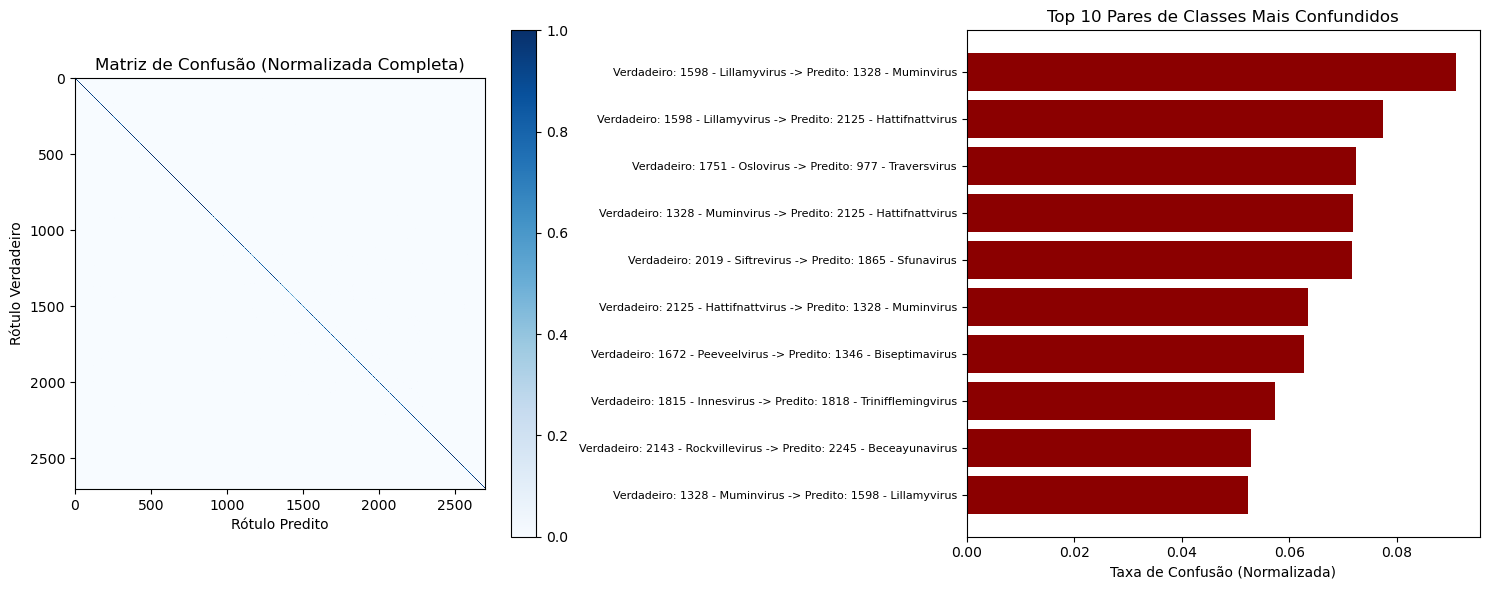

In [11]:
top_k_confused = plot_confusion_matrix_insights(model, test_loader_genus, DEVICE, NUM_CLASSES_genus, top_k_confusion=10,mapping_csv_path = mapping_csv_path_genus, col_name = "genus")

In [12]:
model.cpu() 
weights = model.conv1.weight.data.numpy()

# Shape of weights: (64, 4, 7) -> (Output Channels, Input Channels, Kernel Size)
num_filters = weights.shape[0] # 64
motif_length = weights.shape[2] # 7

most_used_motifs = get_most_used_motiffs(weights,num_filters,motif_length)
most_used_motifs

{'ACTGCTT': 1,
 'CCGCAGC': 1,
 'TGTGTTG': 1,
 'CATCGGA': 1,
 'TGGGGTA': 1,
 'CCCGCCC': 1,
 'TGGCGAC': 1,
 'TTGTTGC': 1,
 'GGAGTAA': 1,
 'TTAAACA': 1,
 'TCGGACT': 1,
 'GCGAGCC': 1,
 'GTGTGGA': 1,
 'GTCGAAC': 1,
 'GAAAAAC': 1,
 'GGGTCCA': 1,
 'TTCGAGA': 1,
 'GGGGGGG': 1,
 'AGCGCGC': 1,
 'GAACGGT': 1,
 'CATGGAG': 1,
 'CGCTCTG': 1,
 'CACGGCA': 1,
 'GTTTAAA': 1,
 'ACTGCCC': 1,
 'GAAAGCA': 1,
 'TATACCA': 1,
 'GTCCTTG': 1,
 'CAAAATA': 1,
 'GTCGGAA': 1,
 'CCCAAGT': 1,
 'TATAACT': 1,
 'TCAGACA': 1,
 'CTAGTGG': 1,
 'TACGACG': 1,
 'GAGTTAT': 1,
 'GCGAAAT': 1,
 'GACTGCG': 1,
 'AGGGCAG': 1,
 'AGCTTTG': 1,
 'GTGGCCA': 1,
 'TTTTTTT': 1,
 'CACTTAT': 1,
 'ATGAAGC': 1,
 'TATAGTA': 1,
 'CACCTGG': 1,
 'TTAAGAA': 1,
 'ACAGAGA': 1,
 'AAAGTTT': 1,
 'GCAGCAA': 1,
 'TCTGCAC': 1,
 'CCGCCGG': 1,
 'CTTCGGA': 1,
 'GGTATAT': 1,
 'CTCGCGT': 1,
 'CTTCGAC': 1,
 'CGAGGAG': 1,
 'TAGGGAA': 1,
 'CGTGCGA': 1,
 'GCCTCCA': 1,
 'GTTCCTC': 1,
 'AGCAACC': 1,
 'TGAATTC': 1,
 'CACCATC': 1}

<h1>ConvNext Genus</h1>

In [13]:
model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES_genus, debug=False, dropout_rate=0.7)
model.to(DEVICE)
try:
    print(f"Carregando pesos de: {PATH_CONVNEXT_genus}")
    state_dict = torch.load(PATH_CONVNEXT_genus)
    
    # Limpeza de chaves se necessário (caso venha de torch.compile)
    new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
    if "model_state_dict" in new_state_dict:
        new_state_dict = new_state_dict["model_state_dict"]
        
    model.load_state_dict(new_state_dict)
    print("Sucesso! Modelo carregado. Iniciando Fase de Refinamento.")
except Exception as e:
    print(f"ATENÇÃO: Não foi possível carregar o checkpoint: {e}")
    print("Verifique o caminho do arquivo. Se prosseguir, será um treino do zero (não recomendado agora).")


Carregando pesos de: ./checkpoint_genus_conv/best_convnext_classifier_fast_phase4_2.pt
Sucesso! Modelo carregado. Iniciando Fase de Refinamento.



--- Coletando Previsões do Modelo para a Matriz de Confusão ---
Mapeamento de espécies carregado e ajustado de '../dataset_kraken/genus_name_ids.csv'.


Coletando Previsões:   0%|          | 0/798 [00:00<?, ?it/s]

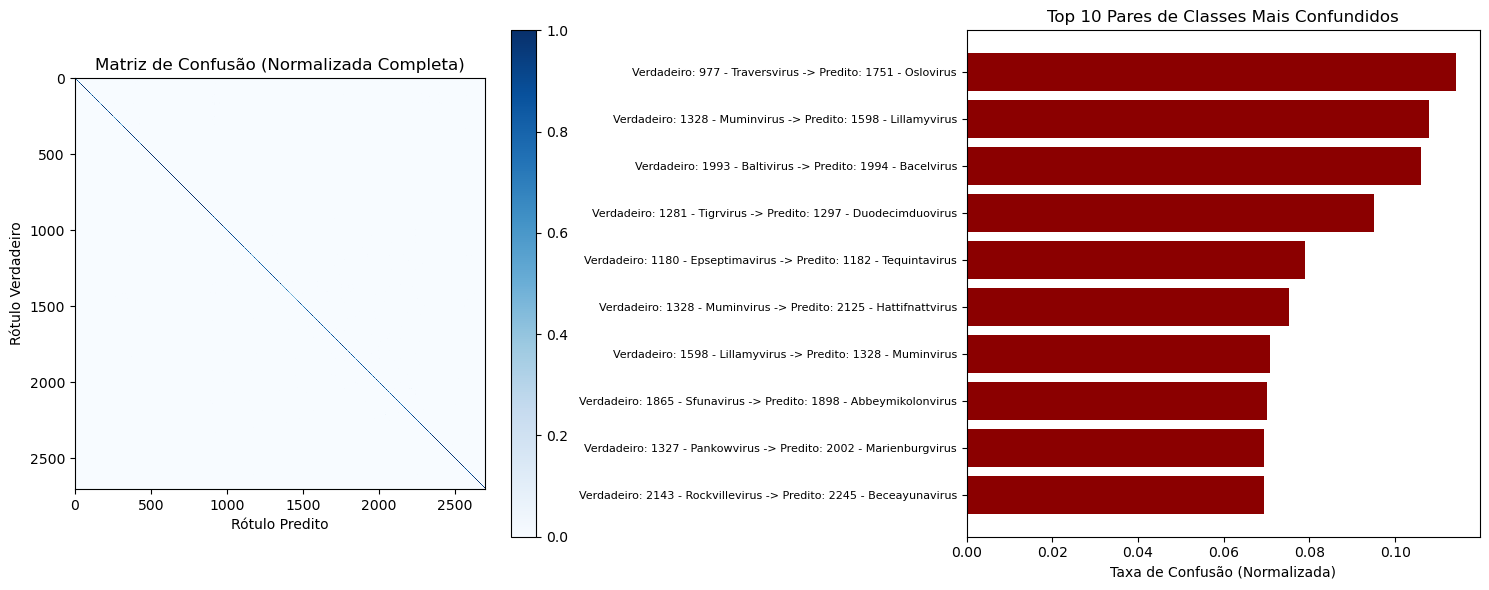

In [14]:
top_k_confused = plot_confusion_matrix_insights(model, test_loader_genus, DEVICE, NUM_CLASSES_genus, top_k_confusion=10,mapping_csv_path = mapping_csv_path_genus, col_name = "genus")

In [15]:
if hasattr(model, 'conv1'):
    first_layer = model.conv1
    print("Detecatado: Hybrid Architecture (usando model.conv1)")
# Fallback para ConvNeXt Pura (caso mude a arquitetura no futuro)
elif hasattr(model, 'downsample_layers'):
    first_layer = model.downsample_layers[0][0] # O Stem
    print("Detectado: Pure ConvNeXt (usando downsample_layers[0])")
else:
    raise ValueError("Não foi possível encontrar a primeira camada convolucional (conv1 ou downsample_layers).")

# Extração dos pesos
# shape esperado: (Out_Channels, In_Channels, Kernel_Size)
# Ex no seu modelo: (64, 4, 7)
weights = first_layer.weight.data.cpu().numpy()

num_filters = weights.shape[0]
kernel_size = weights.shape[2]

print(f"Analisando {num_filters} filtros de tamanho {kernel_size}...")

most_used_motifs = get_most_used_motiffs(weights,num_filters,motif_length)
most_used_motifs


Detecatado: Hybrid Architecture (usando model.conv1)
Analisando 64 filtros de tamanho 7...


{'GAAGATT': 1,
 'CGTACTC': 1,
 'CTGTAAA': 1,
 'TAAAGAT': 1,
 'ATTCGAT': 1,
 'AAGTACA': 1,
 'ACCCGAA': 1,
 'CCGGCGT': 1,
 'CACTGCC': 1,
 'CCTTGGC': 1,
 'ATTGACA': 1,
 'GGCCATA': 1,
 'ATTCGGA': 1,
 'TACCTTG': 1,
 'TGTTGGT': 1,
 'CAGGACC': 1,
 'GGAGCTG': 1,
 'ATCTGGA': 1,
 'GGGAGAT': 1,
 'TGGGCAA': 1,
 'CCCACTG': 1,
 'ATTAGGT': 1,
 'CAAATAT': 1,
 'TAACTGG': 1,
 'CATCTCG': 1,
 'TCCCCTG': 1,
 'TCGACCT': 1,
 'CCGCGTC': 1,
 'AAATTGT': 1,
 'CCTCAAG': 1,
 'GCAGTAA': 1,
 'AACCCCT': 1,
 'AAGCTTG': 1,
 'GTGCCCA': 1,
 'TGTCGGT': 1,
 'TTTCTCG': 1,
 'TTACTAG': 1,
 'TACATAT': 1,
 'TTGTCCA': 1,
 'TGGTTTG': 1,
 'CCGAACA': 1,
 'CCGCTGC': 1,
 'TGACAAA': 1,
 'TCGGTGC': 1,
 'TCAGCTT': 1,
 'GATCGCT': 1,
 'GCGTGTT': 1,
 'CAACGAA': 1,
 'CCCTAGA': 1,
 'AGGCCCA': 1,
 'GCTCGAT': 1,
 'ATACCAG': 1,
 'ATCCGCC': 1,
 'ATCGCTG': 1,
 'TCGAGGG': 1,
 'CAATTAA': 1,
 'GGCGGCA': 1,
 'GCTATGA': 1,
 'GCGCGAG': 1,
 'TTCCTGG': 1,
 'AATAATT': 1,
 'GCACTGA': 1,
 'GCCCTGA': 1,
 'AGCTTAC': 1}

<h1>ResNet Species

In [16]:
model = resnet50_1d(MAX_SEQUENCE_LENGTH,NUM_FEATURES,NUM_CLASSES_species,debug=False,dropout_rate=0.5)
model.to(DEVICE)

# Disable the donated buffer optimization globally
#torch._functorch.config.donated_buffer = False
model = torch.compile(model)

try:
    model.load_state_dict(torch.load(PATH_RESNET_species))
    print(f"Melhor modelo carregado de 'best_resnet_classifier__fast_phase4.pt'.")
except FileNotFoundError:
    print(f"Aviso: não encontrado. O teste usará o modelo no seu estado atual (após a última época de treino).")

print(type(model))
print(type(model).__name__)

Melhor modelo carregado de 'best_resnet_classifier__fast_phase4.pt'.
<class 'torch._dynamo.eval_frame.OptimizedModule'>
OptimizedModule



--- Coletando Previsões do Modelo para a Matriz de Confusão ---
Mapeamento de espécies carregado e ajustado de '../dataset_kraken/species_name_ids.csv'.


Coletando Previsões:   0%|          | 0/1667 [00:00<?, ?it/s]

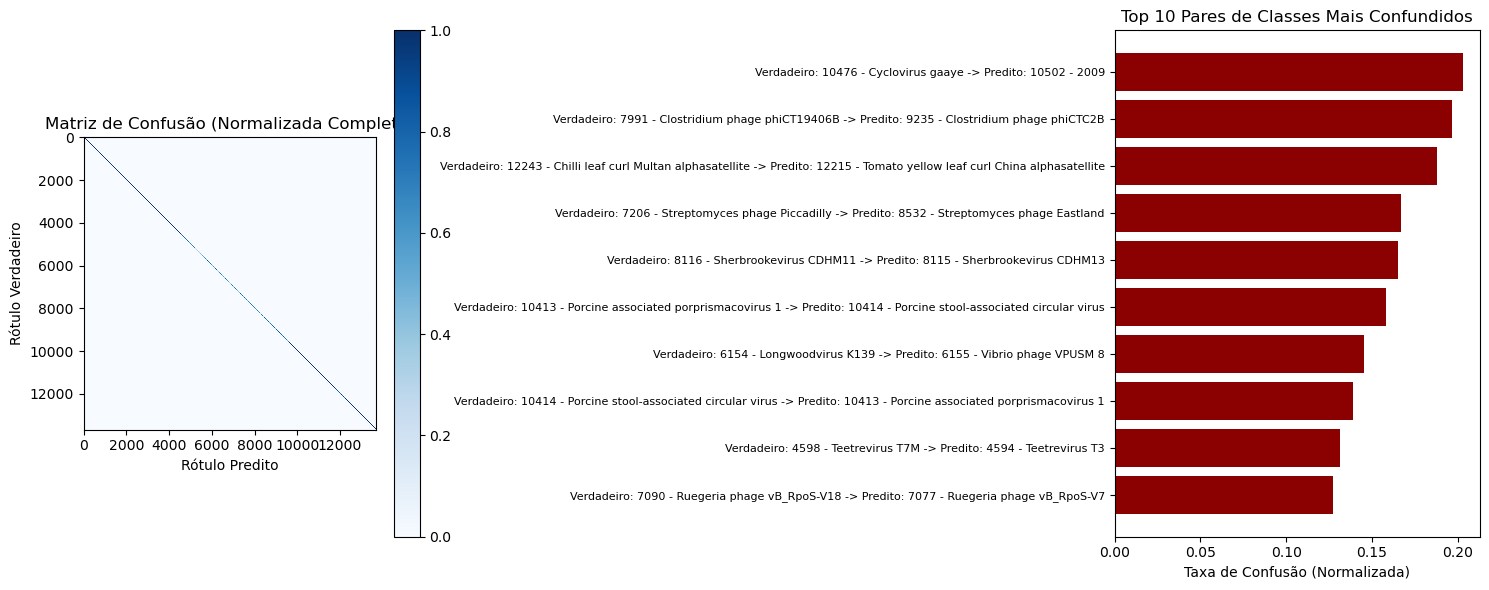

In [17]:
top_k_confused = plot_confusion_matrix_insights(model, test_loader_species, DEVICE, NUM_CLASSES_species, top_k_confusion=10,mapping_csv_path = mapping_csv_path_species, col_name = "species")

In [18]:
model.cpu() 
weights = model.conv1.weight.data.numpy()

# Shape of weights: (64, 4, 7) -> (Output Channels, Input Channels, Kernel Size)
num_filters = weights.shape[0] # 64
motif_length = weights.shape[2] # 7

most_used_motifs = get_most_used_motiffs(weights,num_filters,motif_length)
most_used_motifs

{'ACCCACC': 1,
 'CGAAACT': 1,
 'GCGTGCG': 1,
 'GGCGACT': 1,
 'ACCGGCG': 1,
 'CGGCGCC': 1,
 'TTATACG': 1,
 'ACCGGGG': 1,
 'ATTCGCC': 1,
 'AAAGATC': 1,
 'CCACCCG': 1,
 'CGGCTGG': 1,
 'TGGAGCG': 1,
 'ACACGGA': 1,
 'CTCCGCG': 1,
 'GTCGCAG': 1,
 'GCTCAGA': 1,
 'TCGCACA': 1,
 'TTCGAGT': 1,
 'GTGGTGT': 1,
 'ACCGCTT': 1,
 'TCACGTC': 1,
 'TCGCGCC': 1,
 'CGATCGG': 1,
 'ACTTTTG': 1,
 'CAGTCGA': 1,
 'TTACTCC': 1,
 'AAATCTA': 1,
 'GTGAGTT': 1,
 'GACCGGG': 1,
 'AGGAAGC': 1,
 'GGCGCTT': 1,
 'GCCGCCA': 1,
 'CAGGCAG': 1,
 'GGGTGAC': 1,
 'TCGTGCC': 1,
 'CCCATAT': 1,
 'GATCAGA': 1,
 'TGCCCGC': 1,
 'GTACACG': 1,
 'TGCCTCT': 1,
 'GGCCGGG': 1,
 'TCATCGA': 1,
 'CGGAAAT': 1,
 'GAGAGCG': 1,
 'AGGTCGG': 1,
 'GGGCGCG': 1,
 'CGGCAGT': 1,
 'GGGGGTG': 1,
 'GCGCTGG': 1,
 'TTTTCGT': 1,
 'CCGGCGG': 1,
 'ACGTGGC': 1,
 'TTAGATT': 1,
 'CGCGCTC': 1,
 'TGGTGTC': 1,
 'TTTCACA': 1,
 'AACAACA': 1,
 'GACCTGT': 1,
 'AATTTAG': 1,
 'CCCTCGG': 1,
 'CCACCAG': 1,
 'TAACGCG': 1,
 'GCGCATT': 1}

<h1>ConvNext Species(from scratch)</h1>

In [19]:
model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES_species, debug=False, dropout_rate=0.7)
model.to(DEVICE)
try:
    print(f"Carregando pesos de: {PATH_CONVNEXT_zero_species}")
    state_dict = torch.load(PATH_CONVNEXT_zero_species)
    
    # Limpeza de chaves se necessário (caso venha de torch.compile)
    new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
    if "model_state_dict" in new_state_dict:
        new_state_dict = new_state_dict["model_state_dict"]
        
    model.load_state_dict(new_state_dict)
    print("Sucesso! Modelo carregado. Iniciando Fase de Refinamento.")
except Exception as e:
    print(f"ATENÇÃO: Não foi possível carregar o checkpoint: {e}")
    print("Verifique o caminho do arquivo. Se prosseguir, será um treino do zero (não recomendado agora).")


Carregando pesos de: ./checkpoint_species_conv_zero/best_convnext_phase3_restarts_v2.pt
Sucesso! Modelo carregado. Iniciando Fase de Refinamento.



--- Coletando Previsões do Modelo para a Matriz de Confusão ---
Mapeamento de espécies carregado e ajustado de '../dataset_kraken/species_name_ids.csv'.


Coletando Previsões:   0%|          | 0/1667 [00:00<?, ?it/s]

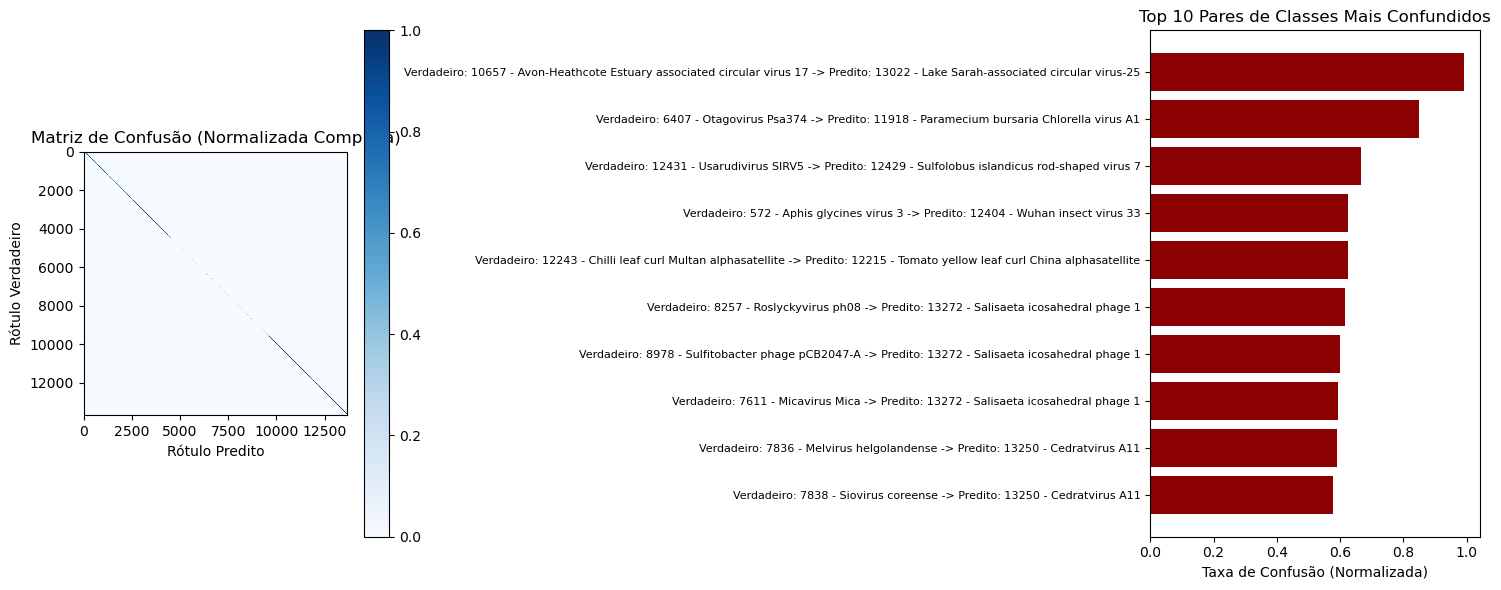

In [20]:
top_k_confused = plot_confusion_matrix_insights(model, test_loader_species, DEVICE, NUM_CLASSES_species, top_k_confusion=10,mapping_csv_path = mapping_csv_path_species, col_name = "species")

In [21]:
if hasattr(model, 'conv1'):
    first_layer = model.conv1
    print("Detecatado: Hybrid Architecture (usando model.conv1)")
# Fallback para ConvNeXt Pura (caso mude a arquitetura no futuro)
elif hasattr(model, 'downsample_layers'):
    first_layer = model.downsample_layers[0][0] # O Stem
    print("Detectado: Pure ConvNeXt (usando downsample_layers[0])")
else:
    raise ValueError("Não foi possível encontrar a primeira camada convolucional (conv1 ou downsample_layers).")

# Extração dos pesos
# shape esperado: (Out_Channels, In_Channels, Kernel_Size)
# Ex no seu modelo: (64, 4, 7)
weights = first_layer.weight.data.cpu().numpy()

num_filters = weights.shape[0]
kernel_size = weights.shape[2]

print(f"Analisando {num_filters} filtros de tamanho {kernel_size}...")

most_used_motifs = get_most_used_motiffs(weights,num_filters,motif_length)
most_used_motifs


Detecatado: Hybrid Architecture (usando model.conv1)
Analisando 64 filtros de tamanho 7...


{'GCGCGCG': 3,
 'GAGTGGC': 1,
 'ACCGCTA': 1,
 'CGCGCGC': 1,
 'CGATTTA': 1,
 'GTTTATT': 1,
 'TAGTACT': 1,
 'ATTAACT': 1,
 'CCCGGGC': 1,
 'TCGGAAT': 1,
 'CTCACCC': 1,
 'AACCGAT': 1,
 'TGCTGCT': 1,
 'TATATGG': 1,
 'AGCAGCA': 1,
 'GGTACTA': 1,
 'GCAGCAG': 1,
 'GAATTCG': 1,
 'ATTTGCG': 1,
 'CCGGCCC': 1,
 'ATTACTA': 1,
 'AGACATA': 1,
 'CAAGCTT': 1,
 'CCTCGGT': 1,
 'CTTATTC': 1,
 'GTAGTAC': 1,
 'TAGGCGC': 1,
 'AAGCGCT': 1,
 'TAGATAT': 1,
 'TCGGTTT': 1,
 'TACCCGC': 1,
 'TATTAAA': 1,
 'CTAGGCG': 1,
 'TTAAGGC': 1,
 'TTAGGCG': 1,
 'CTGCTGC': 1,
 'GGGCGGG': 1,
 'CGCCCCC': 1,
 'ATTAAAA': 1,
 'TAGCTTT': 1,
 'AGGTACC': 1,
 'CGCCTCA': 1,
 'ATGATCA': 1,
 'GATCATG': 1,
 'AAGCTTA': 1,
 'CCCCGCC': 1,
 'CCCGCGC': 1,
 'CGCGGCG': 1,
 'TGATCAT': 1,
 'CGGCCGC': 1,
 'GGTAATC': 1,
 'TCCTTGC': 1,
 'GCGGCCG': 1,
 'CTACAAT': 1,
 'ACCCTCG': 1,
 'GTACTTG': 1,
 'GGCGGGG': 1,
 'GGAGAAG': 1,
 'GGGGGCG': 1,
 'TCTCAGA': 1,
 'GAATAAG': 1,
 'CTTAATC': 1}

<h1>ConvNext Species(from Genus)</h1>

Carregando pesos de: ./checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt
Sucesso! Modelo carregado. Iniciando Fase de Refinamento.

--- Coletando Previsões do Modelo para a Matriz de Confusão ---
Mapeamento de espécies carregado e ajustado de '../dataset_kraken/species_name_ids.csv'.


Coletando Previsões:   0%|          | 0/1667 [00:00<?, ?it/s]

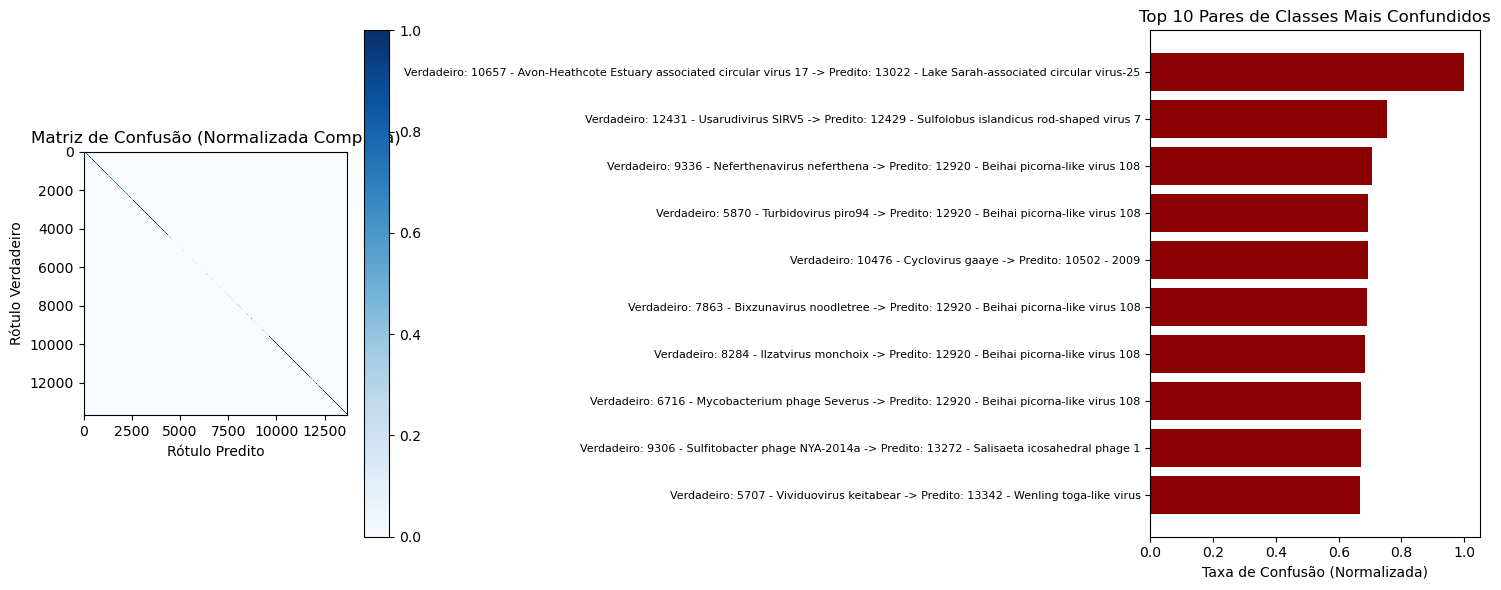

Detecatado: Hybrid Architecture (usando model.conv1)
Analisando 64 filtros de tamanho 7...


{'GGCGGGG': 2,
 'TTGGCAA': 1,
 'ATTCCAA': 1,
 'GGTGCGG': 1,
 'TAACCGG': 1,
 'ATCCGAT': 1,
 'CTATAGC': 1,
 'TCCGCGC': 1,
 'TCGACGA': 1,
 'CTGGCAG': 1,
 'GTCTGAG': 1,
 'GGGGCCC': 1,
 'TCCAGGA': 1,
 'CTTAAGA': 1,
 'GCTGCAG': 1,
 'CGTATTT': 1,
 'GCGCCGG': 1,
 'CCCCCCC': 1,
 'AACTTGG': 1,
 'CCGGTGC': 1,
 'GGGCCCC': 1,
 'TGATCAT': 1,
 'TCTTAAG': 1,
 'TACTAGT': 1,
 'CATGATG': 1,
 'GCAGCTG': 1,
 'CTGCAGC': 1,
 'CGCGCGC': 1,
 'AATAACG': 1,
 'AGTAATG': 1,
 'GCTATAG': 1,
 'AACCGTT': 1,
 'GGGCGAG': 1,
 'GTCGACG': 1,
 'CGTCGAC': 1,
 'TCTCAGA': 1,
 'CTACTAG': 1,
 'TATATAT': 1,
 'GCGCGCG': 1,
 'TGCTGCG': 1,
 'CTCCAGC': 1,
 'AAACGTT': 1,
 'CCGTCGG': 1,
 'TCGGATT': 1,
 'GGCTGCC': 1,
 'CGGACCG': 1,
 'AAGGCTT': 1,
 'AATACGA': 1,
 'CGTGCCA': 1,
 'AGCTGCT': 1,
 'GCCGGGG': 1,
 'ATGATCA': 1,
 'TCTTTTT': 1,
 'GGCCTGC': 1,
 'CATTAAA': 1,
 'TGCAGCA': 1,
 'ACTAGTA': 1,
 'CCCCGCC': 1,
 'CCCCGCG': 1,
 'CGATATT': 1,
 'ATATGTA': 1,
 'CCCCGGT': 1,
 'CCGGTTA': 1}

In [22]:
model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES_species, debug=False, dropout_rate=0.7)
model.to(DEVICE)
try:
    print(f"Carregando pesos de: {PATH_CONVNEXT_transfer_species}")
    state_dict = torch.load(PATH_CONVNEXT_transfer_species)
    
    # Limpeza de chaves se necessário (caso venha de torch.compile)
    new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
    if "model_state_dict" in new_state_dict:
        new_state_dict = new_state_dict["model_state_dict"]
        
    model.load_state_dict(new_state_dict)
    print("Sucesso! Modelo carregado. Iniciando Fase de Refinamento.")
except Exception as e:
    print(f"ATENÇÃO: Não foi possível carregar o checkpoint: {e}")
    print("Verifique o caminho do arquivo. Se prosseguir, será um treino do zero (não recomendado agora).")


top_k_confused = plot_confusion_matrix_insights(model, test_loader_species, DEVICE, NUM_CLASSES_species, top_k_confusion=10,mapping_csv_path = mapping_csv_path_species, col_name = "species")


if hasattr(model, 'conv1'):
    first_layer = model.conv1
    print("Detecatado: Hybrid Architecture (usando model.conv1)")
# Fallback para ConvNeXt Pura (caso mude a arquitetura no futuro)
elif hasattr(model, 'downsample_layers'):
    first_layer = model.downsample_layers[0][0] # O Stem
    print("Detectado: Pure ConvNeXt (usando downsample_layers[0])")
else:
    raise ValueError("Não foi possível encontrar a primeira camada convolucional (conv1 ou downsample_layers).")

# Extração dos pesos
# shape esperado: (Out_Channels, In_Channels, Kernel_Size)
# Ex no seu modelo: (64, 4, 7)
weights = first_layer.weight.data.cpu().numpy()

num_filters = weights.shape[0]
kernel_size = weights.shape[2]

print(f"Analisando {num_filters} filtros de tamanho {kernel_size}...")

most_used_motifs = get_most_used_motiffs(weights,num_filters,motif_length)
most_used_motifs



<h1>ConvNext Species(from FineTuning)</h1>

Carregando pesos de: ./checkpoint_transfer_species_conv/finetune_noise_7.pt
Sucesso! Modelo carregado. Iniciando Fase de Refinamento.

--- Coletando Previsões do Modelo para a Matriz de Confusão ---
Mapeamento de espécies carregado e ajustado de '../dataset_kraken/species_name_ids.csv'.


Coletando Previsões:   0%|          | 0/1667 [00:00<?, ?it/s]

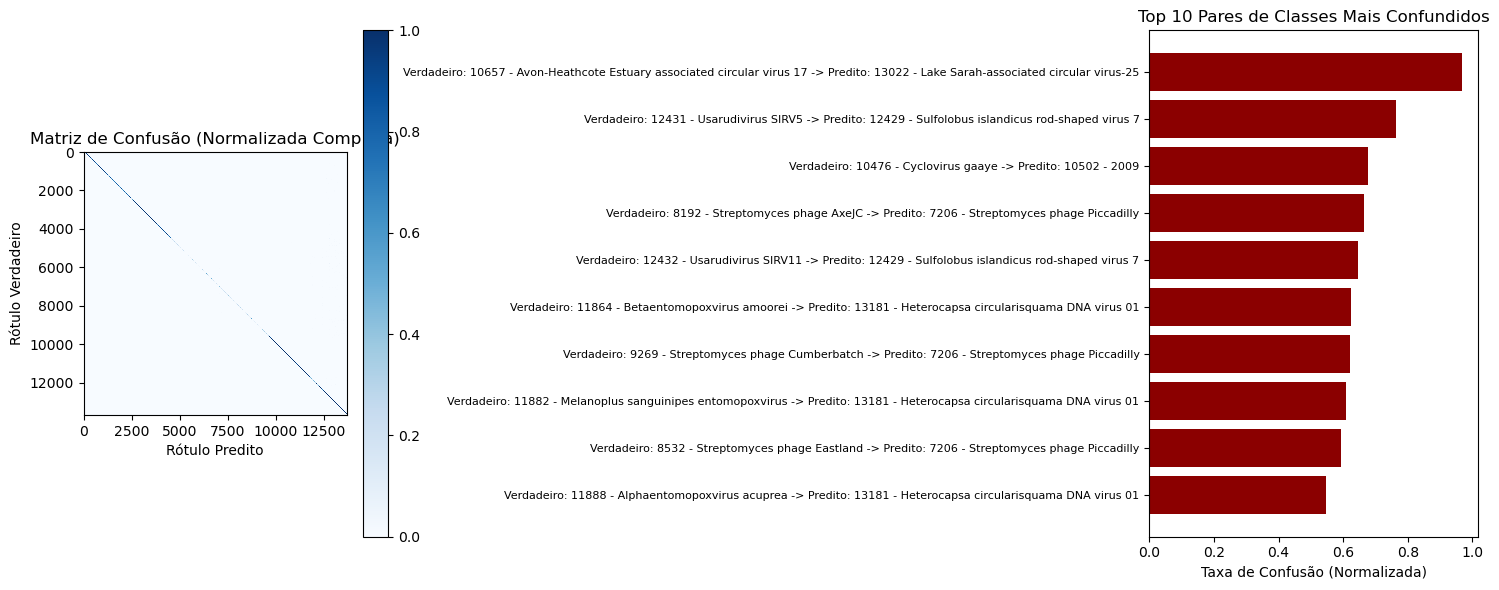

Detecatado: Hybrid Architecture (usando model.conv1)
Analisando 64 filtros de tamanho 7...


{'GGCGGGG': 2,
 'TTCGGAA': 1,
 'ATTCTAC': 1,
 'CGGCCAG': 1,
 'TAACCGG': 1,
 'ATCCGAT': 1,
 'CTATGGC': 1,
 'CCCCGGC': 1,
 'TCGACGA': 1,
 'CAGGCTG': 1,
 'GTCTGAG': 1,
 'GGGGCCC': 1,
 'TCCCGGA': 1,
 'CTTAAGC': 1,
 'GCTGCAG': 1,
 'CGTATTT': 1,
 'TCGCCGG': 1,
 'TCCCCCC': 1,
 'AACTTCT': 1,
 'CCGGTGC': 1,
 'GGGCCCC': 1,
 'TGATCAT': 1,
 'TCTAAAG': 1,
 'TACTAGT': 1,
 'TATCATA': 1,
 'GCAGCTG': 1,
 'CTGCAGC': 1,
 'CGCCCGC': 1,
 'AATAACG': 1,
 'TGTAATG': 1,
 'GCTATGG': 1,
 'AACCGTT': 1,
 'CGGCGAG': 1,
 'GTCGACG': 1,
 'CGCCGAC': 1,
 'ACTCAGA': 1,
 'CTAGTAG': 1,
 'TACATAT': 1,
 'GCCGCCG': 1,
 'GGGGGGA': 1,
 'TGCTGCG': 1,
 'GGCCACC': 1,
 'AAACGTT': 1,
 'CCGTCGG': 1,
 'TCGTATT': 1,
 'GGCTGCG': 1,
 'TGGACGG': 1,
 'ACCGAGT': 1,
 'ACTACGA': 1,
 'CGTGCCA': 1,
 'AGCTGCT': 1,
 'ATGATCA': 1,
 'TGTTTTA': 1,
 'GGCCGGC': 1,
 'CATTAAA': 1,
 'CGCAGCA': 1,
 'ACTAGTA': 1,
 'CCCCCCC': 1,
 'CCCCGCG': 1,
 'CCATATT': 1,
 'ATATGTA': 1,
 'CCCCAGA': 1,
 'CCGGTTA': 1}

In [23]:
model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES_species, debug=False, dropout_rate=0.7)
model.to(DEVICE)
model = torch.compile(model)
try:
    print(f"Carregando pesos de: {PATH_CONVNEXT_fine_species}")
    state_dict = torch.load(PATH_CONVNEXT_fine_species)
    
    # Limpeza de chaves se necessário (caso venha de torch.compile)
    new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
    if "model_state_dict" in new_state_dict:
        new_state_dict = new_state_dict["model_state_dict"]
        
    model.load_state_dict(new_state_dict)
    print("Sucesso! Modelo carregado. Iniciando Fase de Refinamento.")
except Exception as e:
    print(f"ATENÇÃO: Não foi possível carregar o checkpoint: {e}")
    print("Verifique o caminho do arquivo. Se prosseguir, será um treino do zero (não recomendado agora).")


top_k_confused = plot_confusion_matrix_insights(model, test_loader_species, DEVICE, NUM_CLASSES_species, top_k_confusion=10,mapping_csv_path = mapping_csv_path_species, col_name = "species")


if hasattr(model, 'conv1'):
    first_layer = model.conv1
    print("Detecatado: Hybrid Architecture (usando model.conv1)")
# Fallback para ConvNeXt Pura (caso mude a arquitetura no futuro)
elif hasattr(model, 'downsample_layers'):
    first_layer = model.downsample_layers[0][0] # O Stem
    print("Detectado: Pure ConvNeXt (usando downsample_layers[0])")
else:
    raise ValueError("Não foi possível encontrar a primeira camada convolucional (conv1 ou downsample_layers).")

# Extração dos pesos
# shape esperado: (Out_Channels, In_Channels, Kernel_Size)
# Ex no seu modelo: (64, 4, 7)
weights = first_layer.weight.data.cpu().numpy()

num_filters = weights.shape[0]
kernel_size = weights.shape[2]

print(f"Analisando {num_filters} filtros de tamanho {kernel_size}...")

most_used_motifs = get_most_used_motiffs(weights,num_filters,motif_length)
most_used_motifs



In [24]:
top_k_confused

[(np.float64(0.9692307692307692), 10657, 13022),
 (np.float64(0.7631578947368421), 12431, 12429),
 (np.float64(0.6783216783216783), 10476, 10502),
 (np.float64(0.6639344262295082), 8192, 7206),
 (np.float64(0.646551724137931), 12432, 12429),
 (np.float64(0.624), 11864, 13181),
 (np.float64(0.6224489795918368), 9269, 7206),
 (np.float64(0.608), 11882, 13181),
 (np.float64(0.5942028985507246), 8532, 7206),
 (np.float64(0.5454545454545454), 11888, 13181)]

In [25]:
confused_pairs = []
mapping_csv_path=mapping_csv_path_species
for confused_pair in top_k_confused:
    species1=get_class_label(mapping_csv_path, confused_pair[1],col_name = "species")
    species2=get_class_label(mapping_csv_path, confused_pair[2],col_name = "species")
    confused_pairs.append([species1,species2])
#rename for nbci
for i in range(len(confused_pairs)):
    for j in range(2):
        if confused_pairs[i][j] == "2009":
            confused_pairs[i][j] = "Cyclovirus PKbeef23/PAK/2009"
        if confused_pairs[i][j] == "Porcine stool-associated circular virus":
            confused_pairs[i][j] = "Porcine associated stool circular virus"
        if confused_pairs[i][j] == "Tomato yellow leaf curl China alphasatellite":
            confused_pairs[i][j] = "Tomato yellow leaf curl China virus alphasatellite"
confused_pairs

[['Avon-Heathcote Estuary associated circular virus 17',
  'Lake Sarah-associated circular virus-25'],
 ['Usarudivirus SIRV5', 'Sulfolobus islandicus rod-shaped virus 7'],
 ['Cyclovirus gaaye', 'Cyclovirus PKbeef23/PAK/2009'],
 ['Streptomyces phage AxeJC', 'Streptomyces phage Piccadilly'],
 ['Usarudivirus SIRV11', 'Sulfolobus islandicus rod-shaped virus 7'],
 ['Betaentomopoxvirus amoorei', 'Heterocapsa circularisquama DNA virus 01'],
 ['Streptomyces phage Cumberbatch', 'Streptomyces phage Piccadilly'],
 ['Melanoplus sanguinipes entomopoxvirus',
  'Heterocapsa circularisquama DNA virus 01'],
 ['Streptomyces phage Eastland', 'Streptomyces phage Piccadilly'],
 ['Alphaentomopoxvirus acuprea', 'Heterocapsa circularisquama DNA virus 01']]

In [26]:
import requests
import time
from Bio import Entrez, SeqIO, pairwise2
from Bio.pairwise2 import format_alignment

# --- Configuration ---
# 1. NCBI requires an email address for Entrez access. Please change 'your.email@example.com' 
#    to your actual email address.
Entrez.email = "matheuslimaaa13@gmail.com"
# 2. Add an API Key (optional but highly recommended for better rate limits)
#    Entrez.api_key = "YOUR_NCBI_API_KEY"

def search_and_fetch_sequence(species_name: str, db: str = "nuccore") -> tuple[str, str] | None:
    """
    Searches the NCBI database for a sequence corresponding to the species name
    and fetches its FASTA sequence.
    """
    print(f"--- Searching for: {species_name} ---")
    
    # 1. Search for the relevant accession ID (the first result is usually sufficient)
    try:
        #handle = Entrez.esearch(db=db, term=f'{species_name}[organism] AND complete genome', retmax="1")
        handle = Entrez.esearch(db=db, term=f'{species_name}[organism]', retmax="1")
        record = Entrez.read(handle)
        handle.close()
        
        if not record["IdList"]:
            print(f"Error: Could not find an ID for '{species_name}'.")
            return None
        
        accession_id = record["IdList"][0]
        print(f"Found Accession ID: {accession_id}")
        
        # 2. Fetch the actual sequence record
        handle = Entrez.efetch(db=db, id=accession_id, rettype="fasta", retmode="text")
        # Use SeqIO.read to parse the FASTA data from the handle
        sequence_record = SeqIO.read(handle, "fasta")
        handle.close()
        
        # We need the sequence itself (as a string) and a descriptive identifier
        identifier = sequence_record.id
        sequence = str(sequence_record.seq)
        print(f"Fetched sequence of length: {len(sequence)}")
        
        return identifier, sequence
    
    except requests.exceptions.HTTPError as e:
        print(f"An HTTP error occurred during Entrez request (check rate limits or API key): {e}")
        return None
    except Exception as e:
        print(f"An unexpected error occurred during sequence fetching: {e}")
        return None

def run_pairwise_alignment(name1: str, seq1: str, name2: str, seq2: str):
    """
    Performs a global pairwise alignment using Biopython's pairwise2 module.
    
    We use the global alignment function 'globalxx' which uses the standard 
    scoring matrix for match/mismatch but applies no gap penalties (x, x).
    You can adjust the scoring (e.g., globalms for specific match/mismatch/gap scores).
    """
    print("\n--- Running Pairwise Alignment (Global Alignment) ---")
    
    # Define alignment parameters:
    # Match score: 2, Mismatch score: -1, Gap open penalty: -0.5, Gap extend penalty: -0.1
    match_score = 2
    mismatch_score = -1
    gap_open = -0.5
    gap_extend = -0.1
    
    # We use globalms (global alignment with match/mismatch and specific gap scores)
    alignments = pairwise2.align.globalms(
        seq1, seq2, 
        match_score, mismatch_score, 
        gap_open, gap_extend, 
        one_alignment_only=True # We only need the best single alignment
    )
    
    if not alignments:
        print("Alignment failed to produce results.")
        return

    # Extract the best alignment
    best_alignment = alignments[0]
    aligned_seq1, aligned_seq2, score, begin, end = best_alignment
    
    # Calculate sequence identity (simple exact match identity)
    total_length = len(aligned_seq1)
    match_count = sum(1 for a, b in zip(aligned_seq1, aligned_seq2) if a == b and a != '-')
    # Use the length of the shortest sequence as the denominator for identity, 
    # since global alignment forces alignment over the entire length.
    identity = (match_count / min(len(seq1), len(seq2))) * 100 if min(len(seq1), len(seq2)) > 0 else 0

    result_as_str = "\n--- Alignment Results ---" + \
    f"Sequence 1 ({name1}) length: {len(seq1)}" + \
    f"Sequence 2 ({name2}) length: {len(seq2)}" + \
    f"Alignment Score: {score:.2f}" + \
    f"Calculated Identity (based on original sequence length): {identity:.2f}%" + \
    "\nFormatted Alignment (First 500 characters):" + \
    format_alignment(*best_alignment, full_sequences=True)

    return identity, score, result_as_str

def compare_species(species_1, species2):
    # --- Input Virus Species Names (Representative of different Genera) ---
    virus_name_1 = species_1
    virus_name_2 = species2 # SARS-CoV-2
    
    # 1. Fetch sequence for the first virus
    result1 = search_and_fetch_sequence(virus_name_1)
    if not result1:
        print(f"Cannot proceed without sequence for {virus_name_1}.")
        return None 
        
    id1, sequence1 = result1
    time.sleep(1) # Be courteous to NCBI servers
    
    # 2. Fetch sequence for the second virus
    result2 = search_and_fetch_sequence(virus_name_2)
    if not result2:
        print(f"Cannot proceed without sequence for {virus_name_2}.")
        return None 
    
    id2, sequence2 = result2
    
    # 3. Run the pairwise alignment
    # This result will demonstrate the large difference (low identity) between 
    # two members of different genera, illustrating their 'distance'.
    identity, score, result_as_str = run_pairwise_alignment(id1, sequence1, id2, sequence2)
    return identity, score, result_as_str

results =[]
for confused_pair in confused_pairs:
    retorno = compare_species(confused_pair[0], confused_pair[1])
    if retorno is not None:
        identity, score, result_as_str = retorno
        results.append((confused_pair,identity, score, result_as_str))


    

/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


--- Searching for: Avon-Heathcote Estuary associated circular virus 17 ---
Found Accession ID: 765702669
Fetched sequence of length: 1741
--- Searching for: Lake Sarah-associated circular virus-25 ---
Found Accession ID: 1003725753
Fetched sequence of length: 1776

--- Running Pairwise Alignment (Global Alignment) ---
--- Searching for: Usarudivirus SIRV5 ---
Found Accession ID: 1197509205
Fetched sequence of length: 35439
--- Searching for: Sulfolobus islandicus rod-shaped virus 7 ---
Found Accession ID: 1197508893
Fetched sequence of length: 34190

--- Running Pairwise Alignment (Global Alignment) ---
--- Searching for: Cyclovirus gaaye ---
Found Accession ID: 316989865
Fetched sequence of length: 1838
--- Searching for: Cyclovirus PKbeef23/PAK/2009 ---
Found Accession ID: 1464307805
Fetched sequence of length: 1838

--- Running Pairwise Alignment (Global Alignment) ---
--- Searching for: Streptomyces phage AxeJC ---
Found Accession ID: 2489486229
Fetched sequence of length: 37765
--

In [27]:
for result in results:
    confused_pair, identity, score, result_as_str = result
    print(f"Comparando {confused_pair[0]} e {confused_pair[1]}")
    print(f"identidade:{identity}")
    print(f"score:{score}")
    print("=========================")

Comparando Avon-Heathcote Estuary associated circular virus 17 e Lake Sarah-associated circular virus-25
identidade:99.71280873061458
score:3464.700000000003
Comparando Usarudivirus SIRV5 e Sulfolobus islandicus rod-shaped virus 7
identidade:96.67446621819245
score:65368.10000000174
Comparando Cyclovirus gaaye e Cyclovirus PKbeef23/PAK/2009
identidade:100.0
score:3676.0
Comparando Streptomyces phage AxeJC e Streptomyces phage Piccadilly
identidade:95.28020455998295
score:70285.90000000107
Comparando Usarudivirus SIRV11 e Sulfolobus islandicus rod-shaped virus 7
identidade:88.40988128072911
score:56579.40000000436
Comparando Betaentomopoxvirus amoorei e Heterocapsa circularisquama DNA virus 01
identidade:100.0
score:-21422.39999996125
Comparando Streptomyces phage Cumberbatch e Streptomyces phage Piccadilly
identidade:96.09524824206265
score:71119.40000000125
Comparando Melanoplus sanguinipes entomopoxvirus e Heterocapsa circularisquama DNA virus 01
identidade:100.0
score:-21795.5999999

In [58]:
%load_ext autoreload
%autoreload 2

from utils.analize_funcs import *
from utils.gradcam import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [51]:
confused_samples = get_confused_class_samples(top_k_confused,test_loader_species, DEVICE,2)


Passo 1: Coletando tensores de input para as classes alvo...


Coletando Amostras:   0%|          | 0/1667 [00:00<?, ?it/s]

terminate called without an active exception
terminate called without an active exception
terminate called without an active exception
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2185576e80>
Traceback (most recent call last):
  File "/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1654, in __del__
    self._shutdown_workers()
  File "/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1618, in _shutdown_workers
    w.join(timeout=_utils.MP_STATUS_CHECK_INTERVAL)
  File "/home/mlima/workspace/envs/rapids-new/lib/python3.12/multiprocessing/process.py", line 149, in join
    res = self._popen.wait(timeout)
          ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/mlima/workspace/envs/rapids-new/lib/python3.12/multiprocessing/popen_fork.py", line 40, in wait
    if not wait([self.sentinel], timeout):
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/


Passo 2: Formatando os resultados finais.


In [46]:
model.layer4[2].dwconv

Conv1d(2048, 2048, kernel_size=(7,), stride=(1,), padding=(3,), groups=2048)

O modelo atual não parece estar encapsulado pelo torch.compile ou já é o original.

--- Análise de Confusão: Verdadeiro (10657)=10657 - Avon-Heathcote Estuary associated circular virus 17 -> Predito (13022)=13022 - Lake Sarah-associated circular virus-25 | Score Confusão: 0.9692 ---


<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


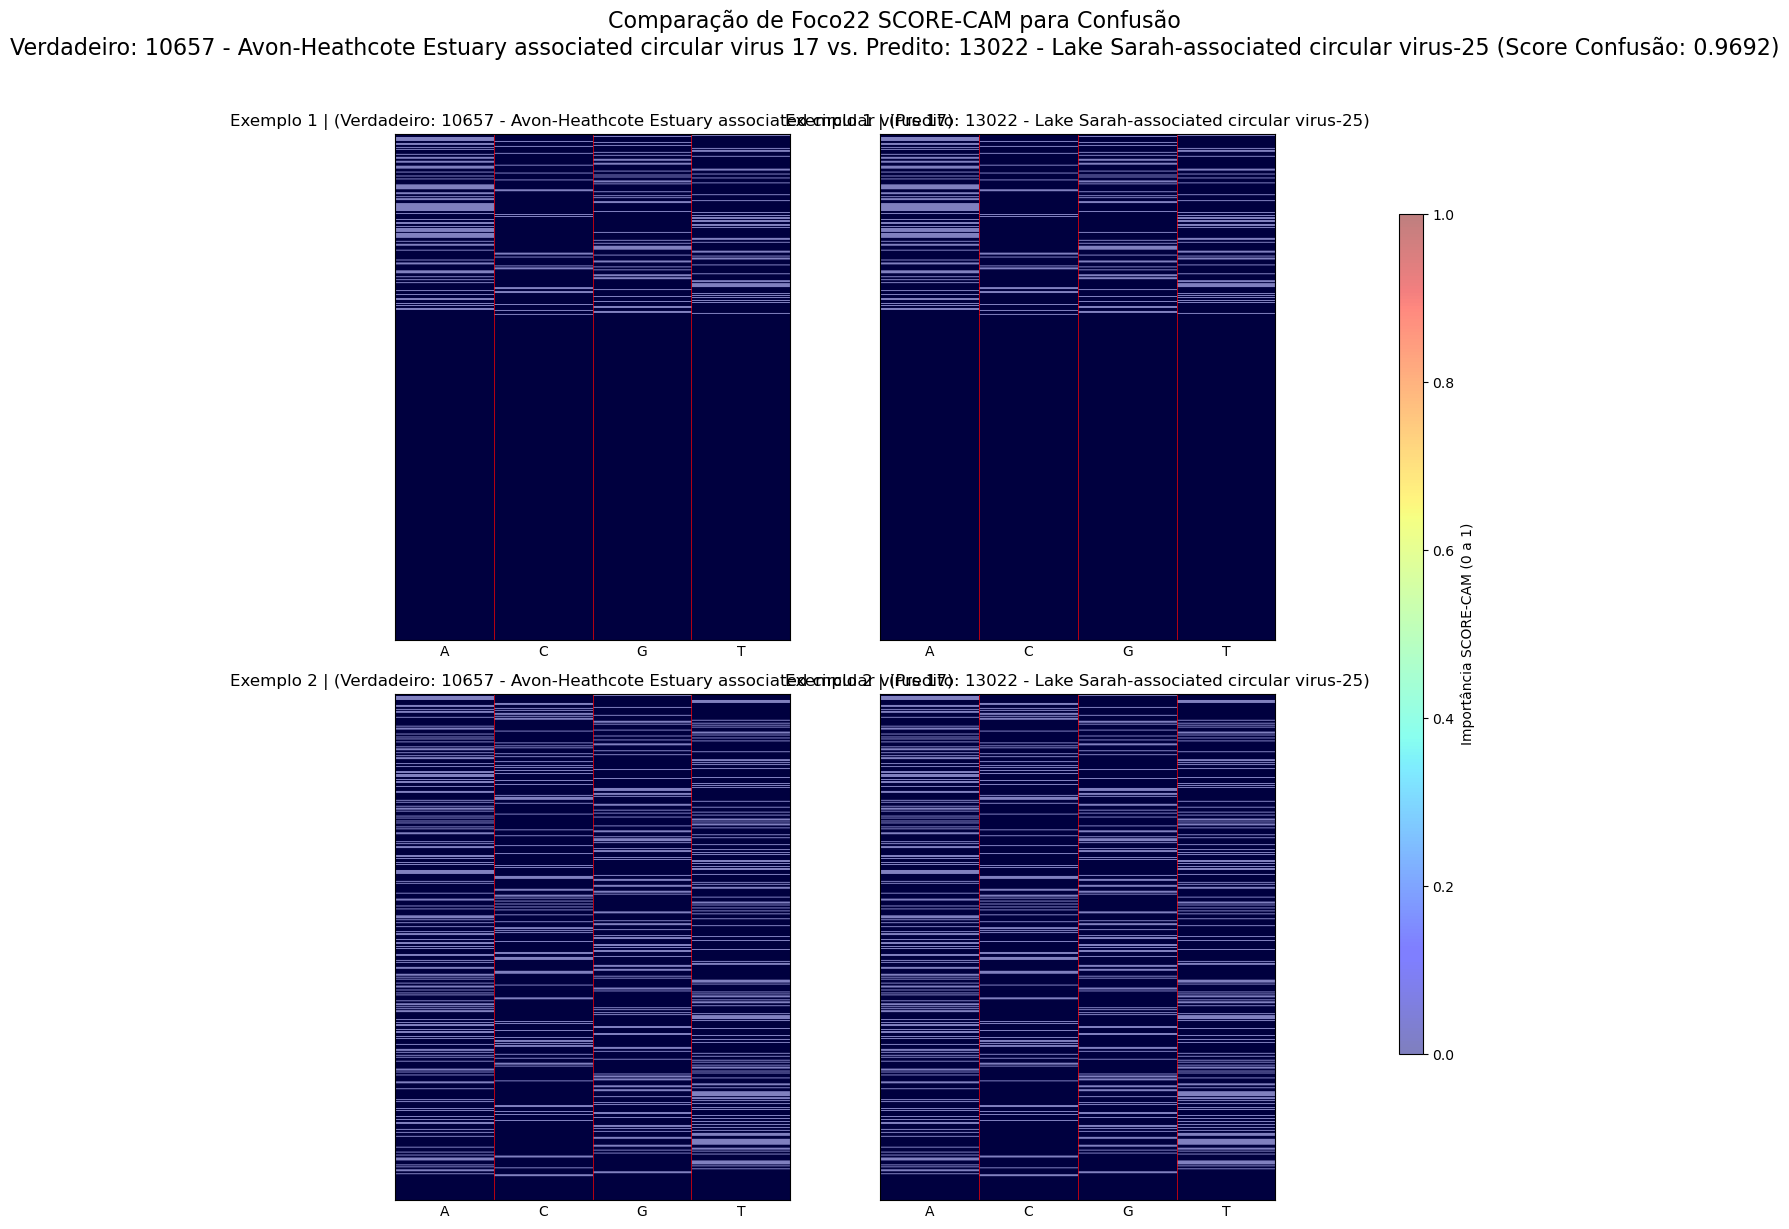


--- Análise de Confusão: Verdadeiro (12431)=12431 - Usarudivirus SIRV5 -> Predito (12429)=12429 - Sulfolobus islandicus rod-shaped virus 7 | Score Confusão: 0.7632 ---


<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


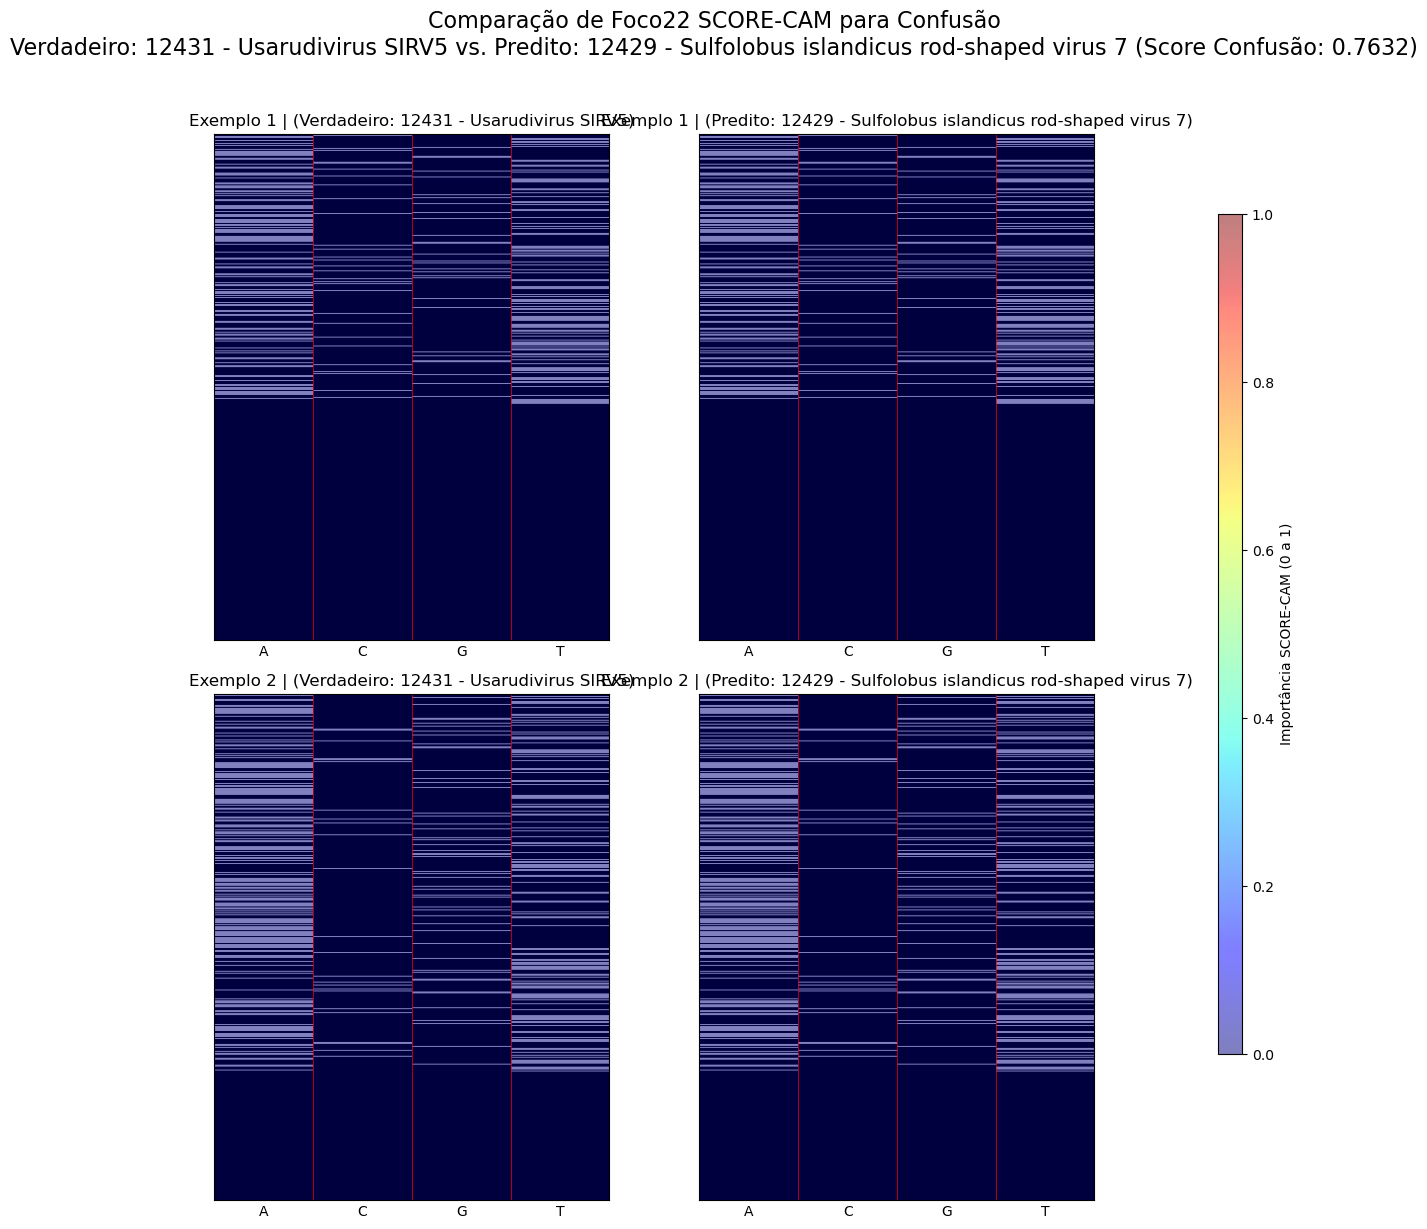


--- Análise de Confusão: Verdadeiro (10476)=10476 - Cyclovirus gaaye -> Predito (10502)=10502 - 2009 | Score Confusão: 0.6783 ---


<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


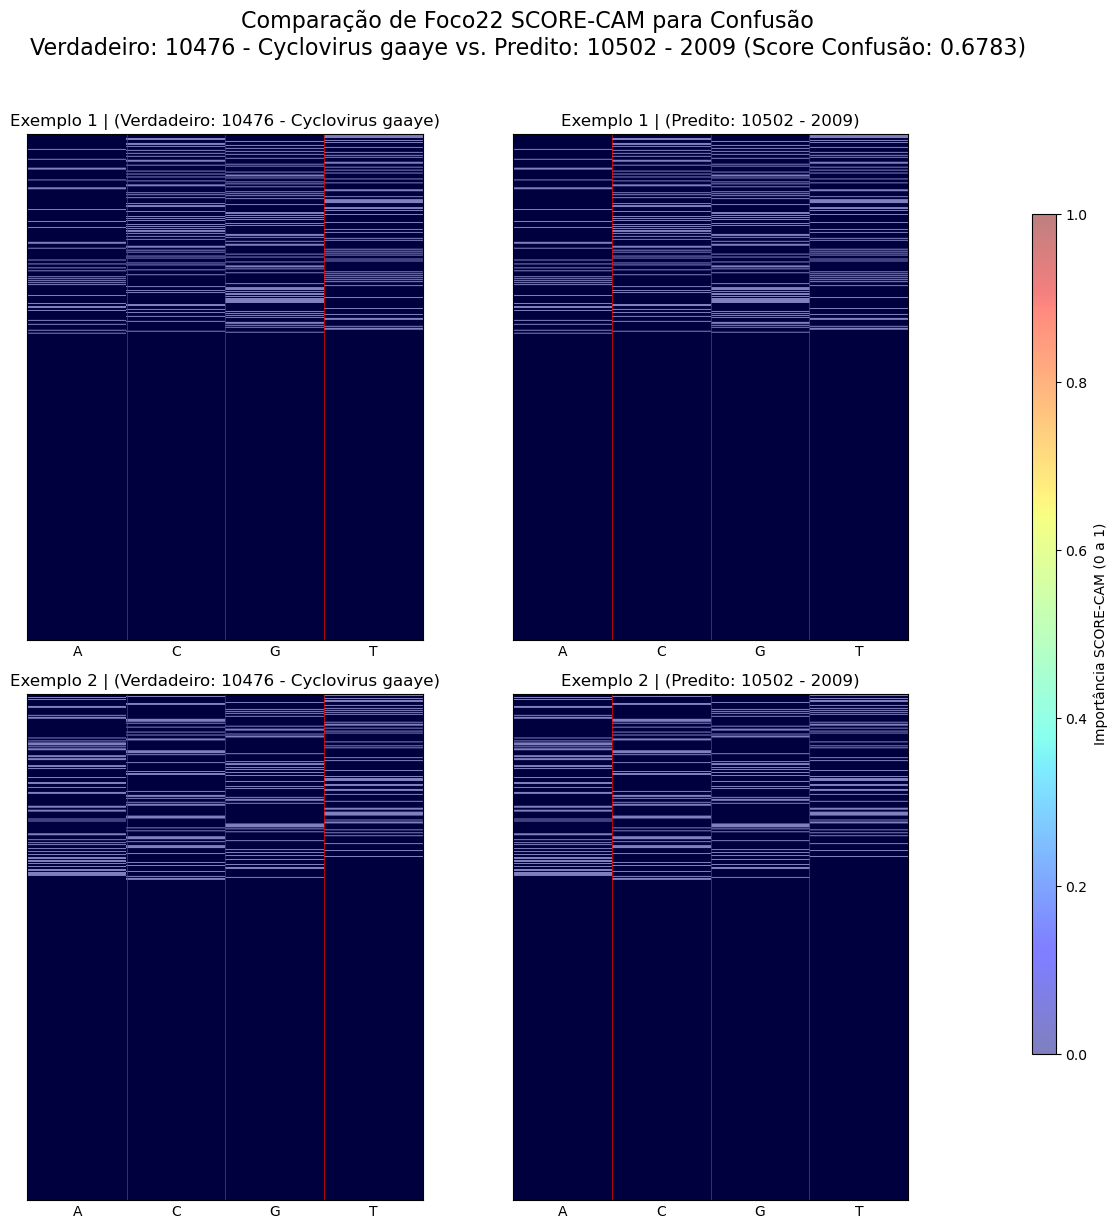


--- Análise de Confusão: Verdadeiro (8192)=8192 - Streptomyces phage AxeJC -> Predito (7206)=7206 - Streptomyces phage Piccadilly | Score Confusão: 0.6639 ---


<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


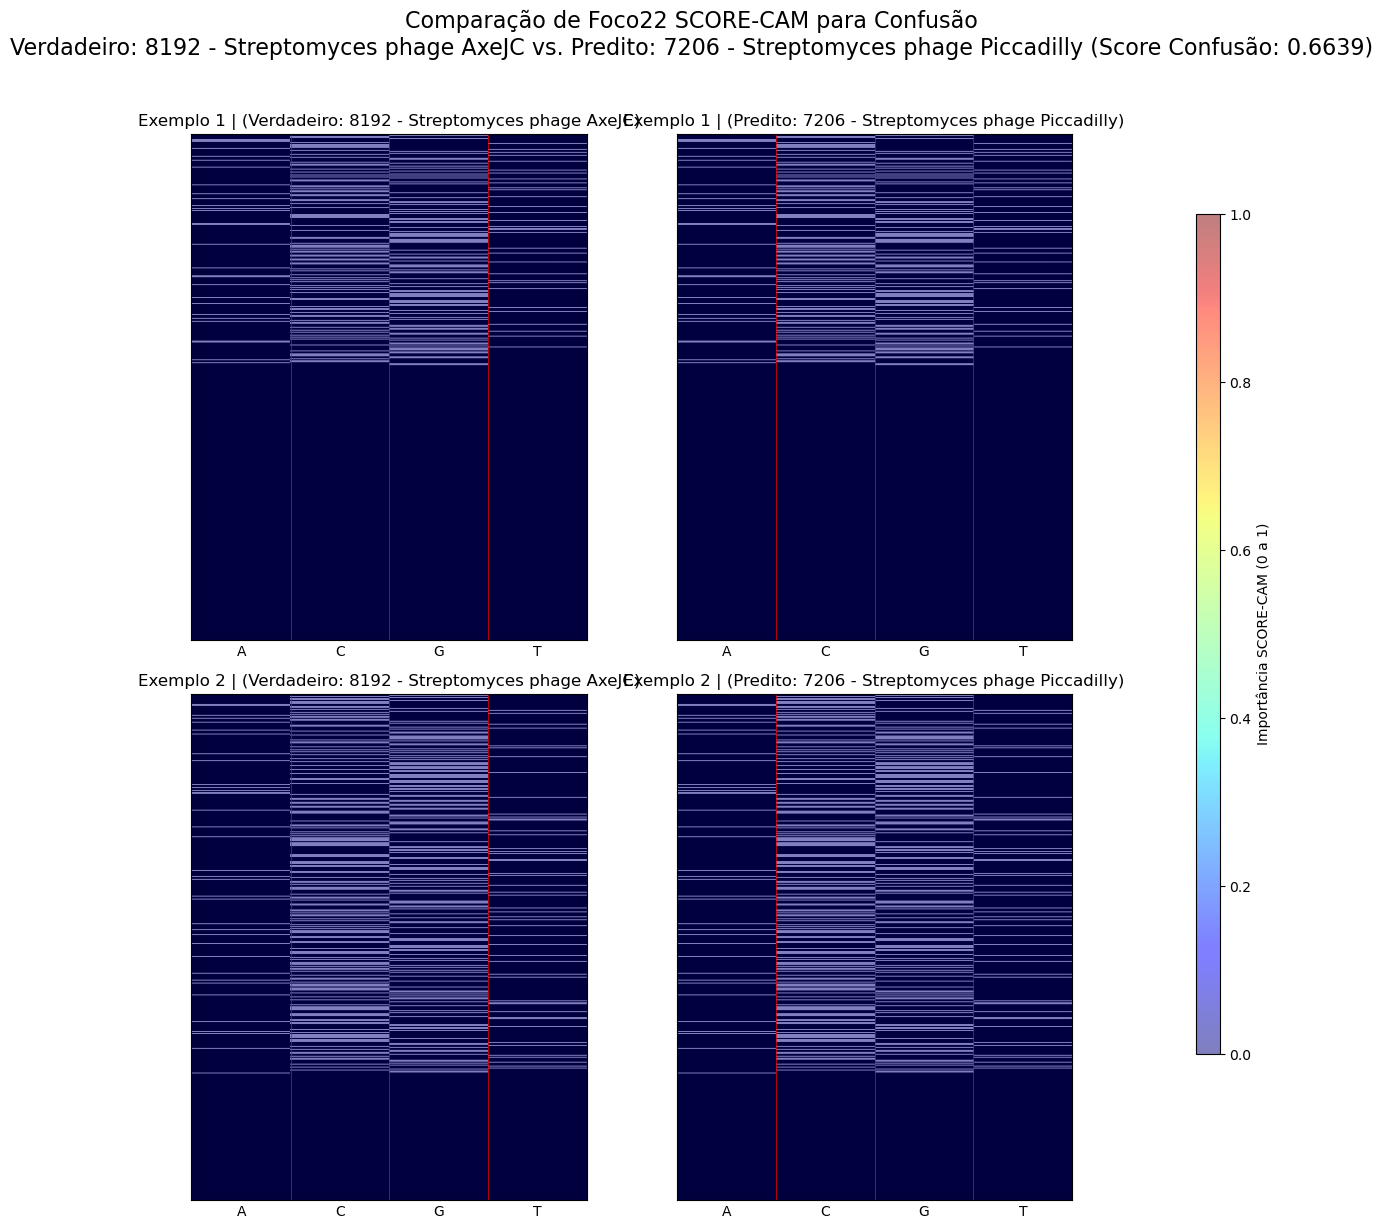


--- Análise de Confusão: Verdadeiro (12432)=12432 - Usarudivirus SIRV11 -> Predito (12429)=12429 - Sulfolobus islandicus rod-shaped virus 7 | Score Confusão: 0.6466 ---


<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


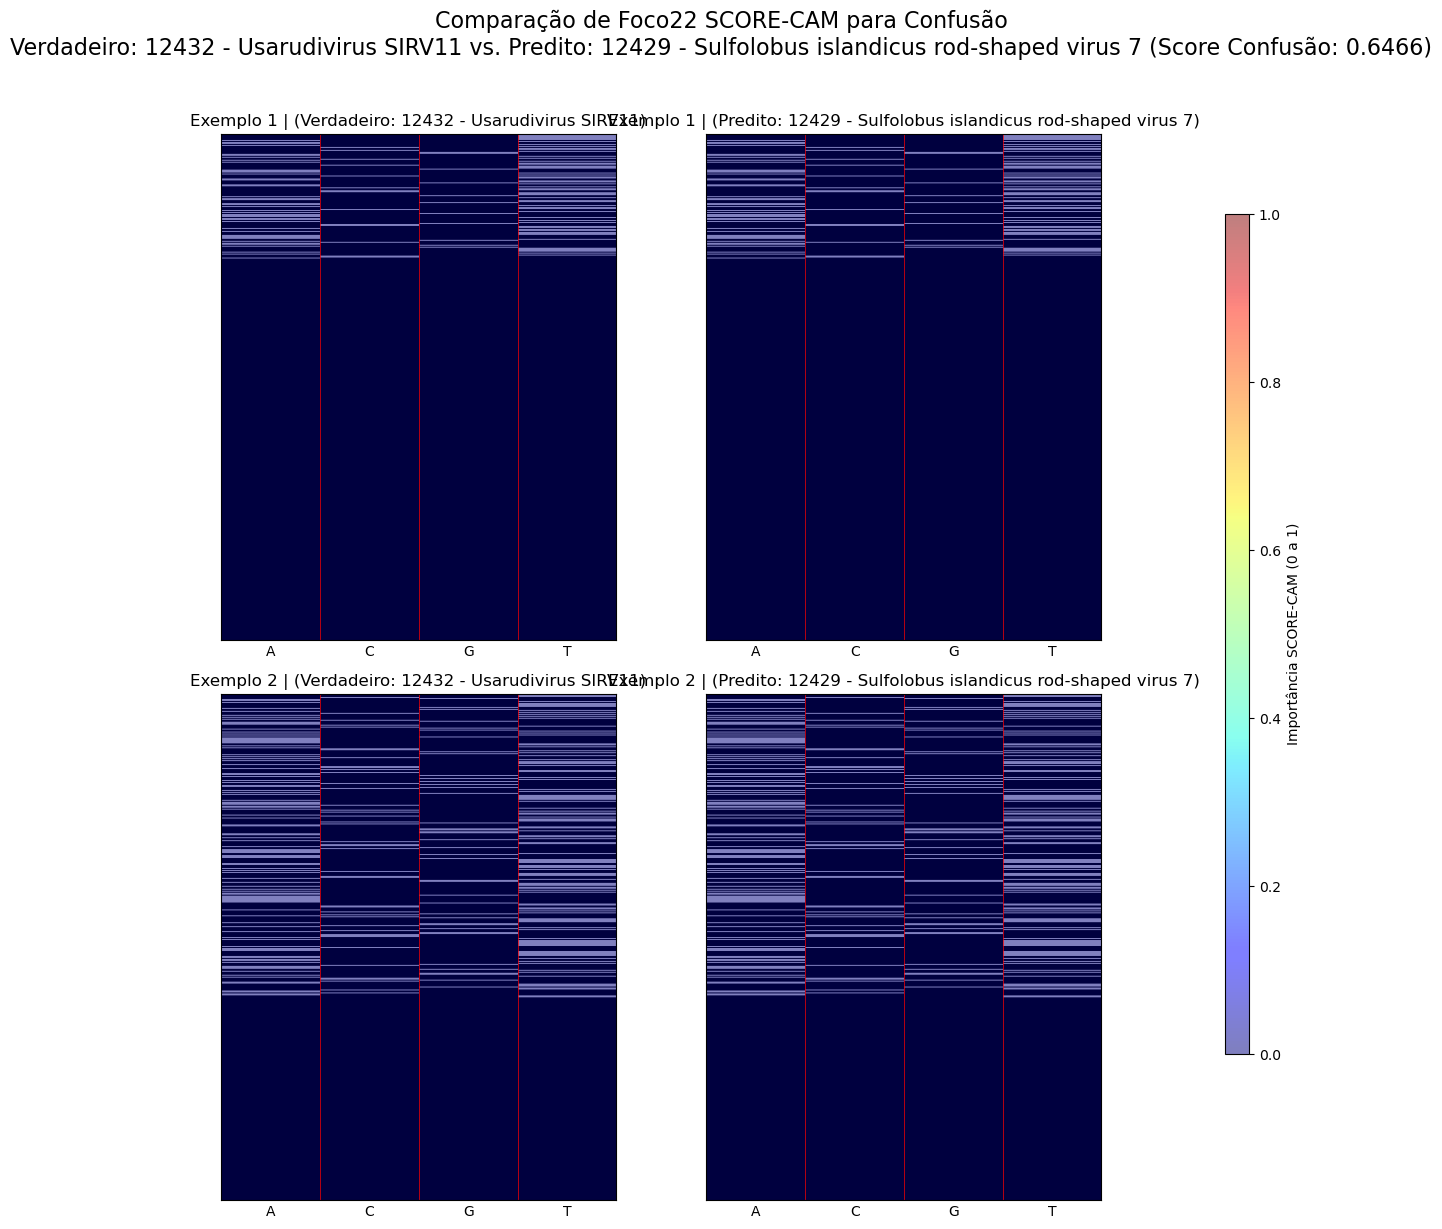


--- Análise de Confusão: Verdadeiro (11864)=11864 - Betaentomopoxvirus amoorei -> Predito (13181)=13181 - Heterocapsa circularisquama DNA virus 01 | Score Confusão: 0.6240 ---


<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


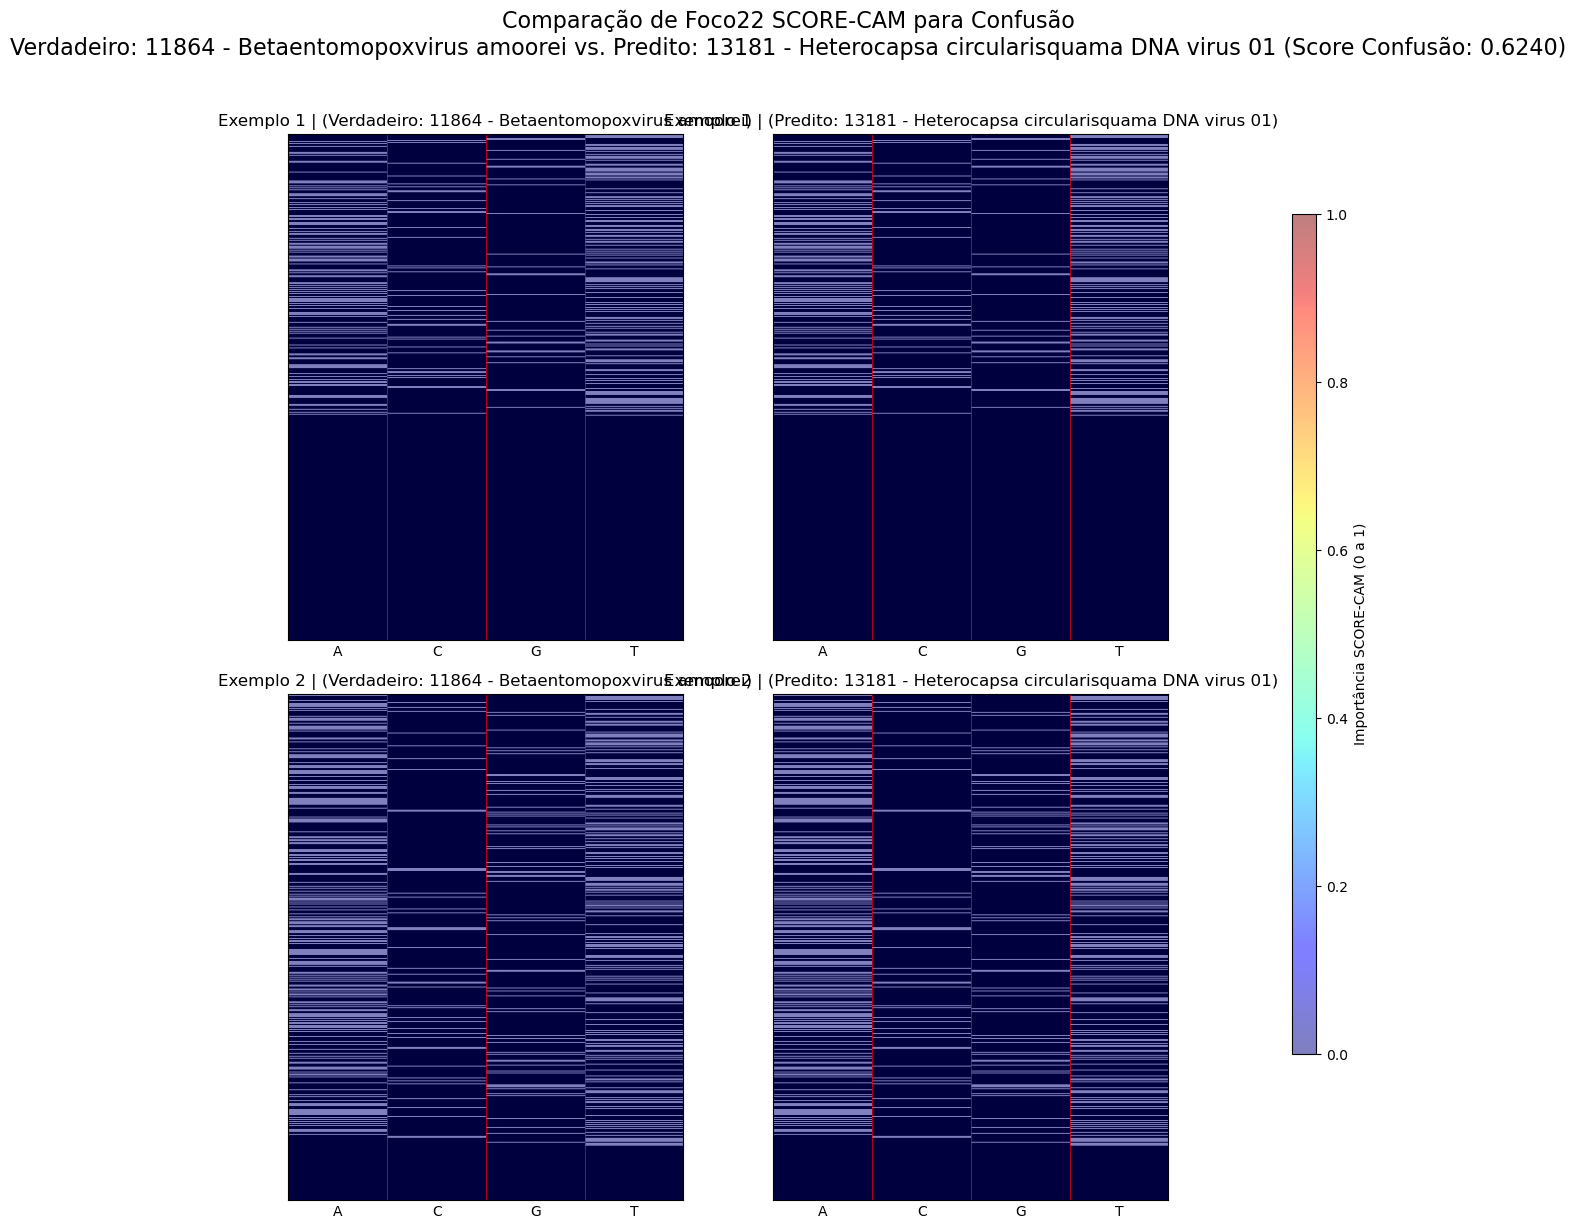


--- Análise de Confusão: Verdadeiro (9269)=9269 - Streptomyces phage Cumberbatch -> Predito (7206)=7206 - Streptomyces phage Piccadilly | Score Confusão: 0.6224 ---


<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


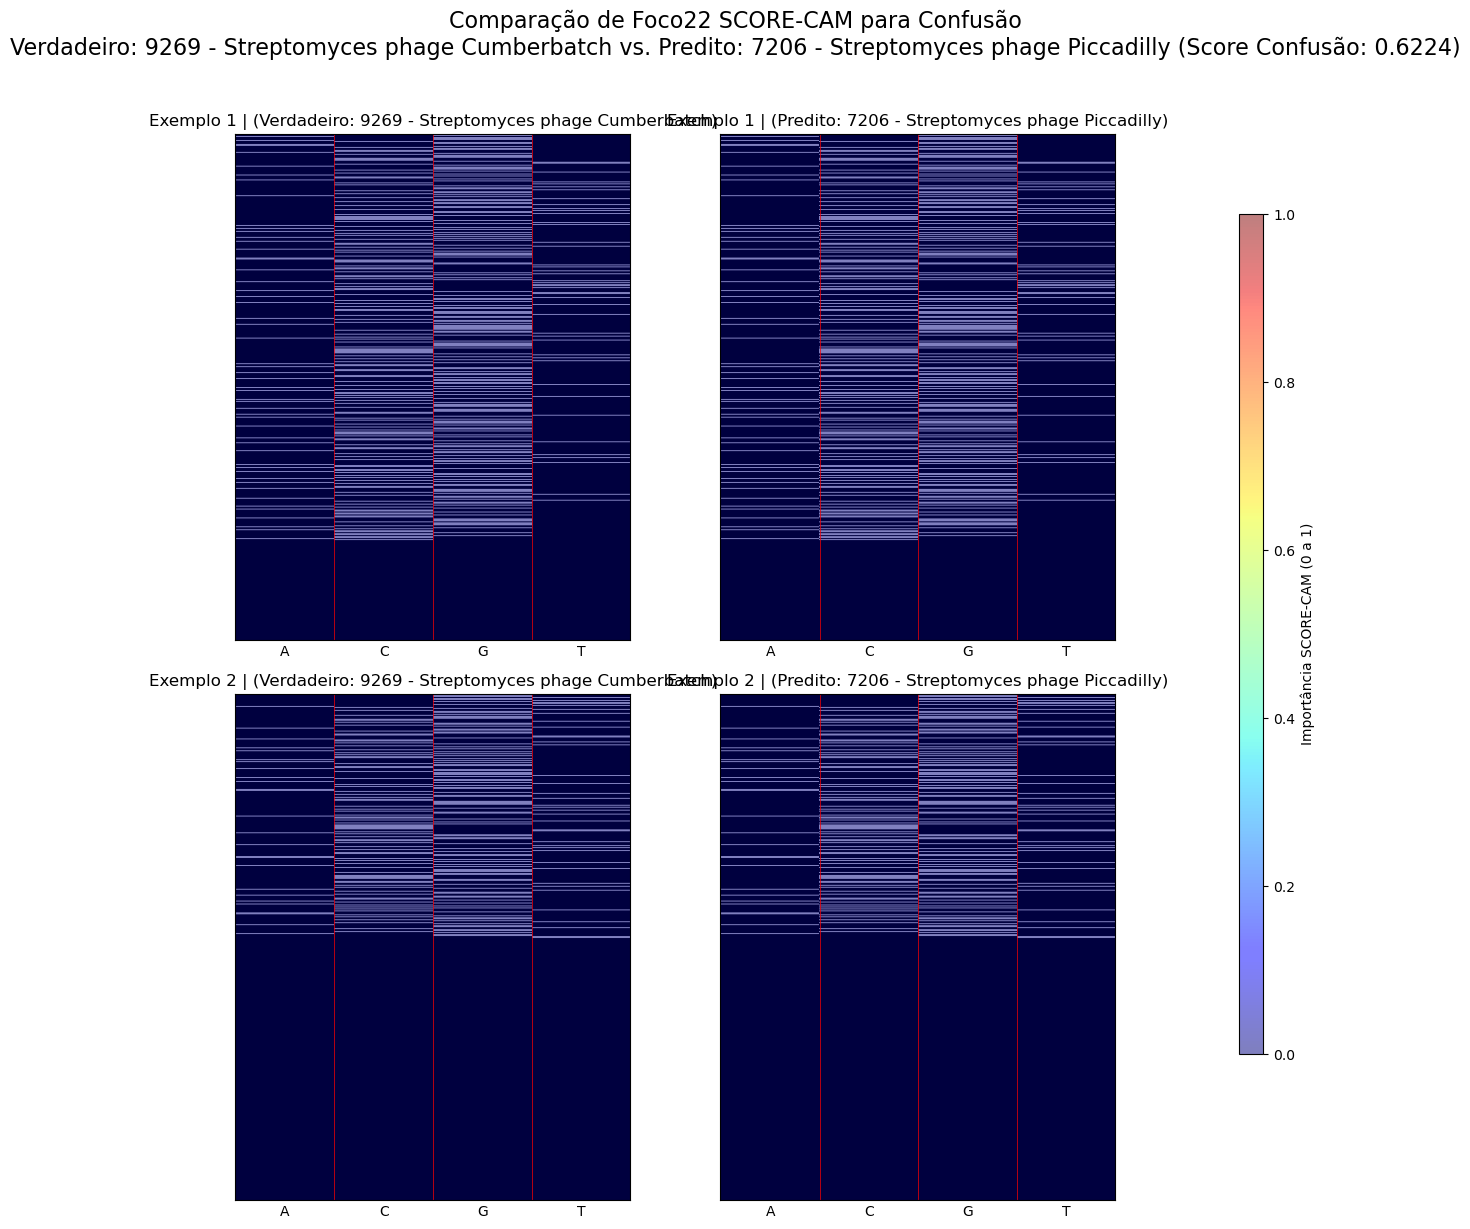


--- Análise de Confusão: Verdadeiro (11882)=11882 - Melanoplus sanguinipes entomopoxvirus -> Predito (13181)=13181 - Heterocapsa circularisquama DNA virus 01 | Score Confusão: 0.6080 ---


<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


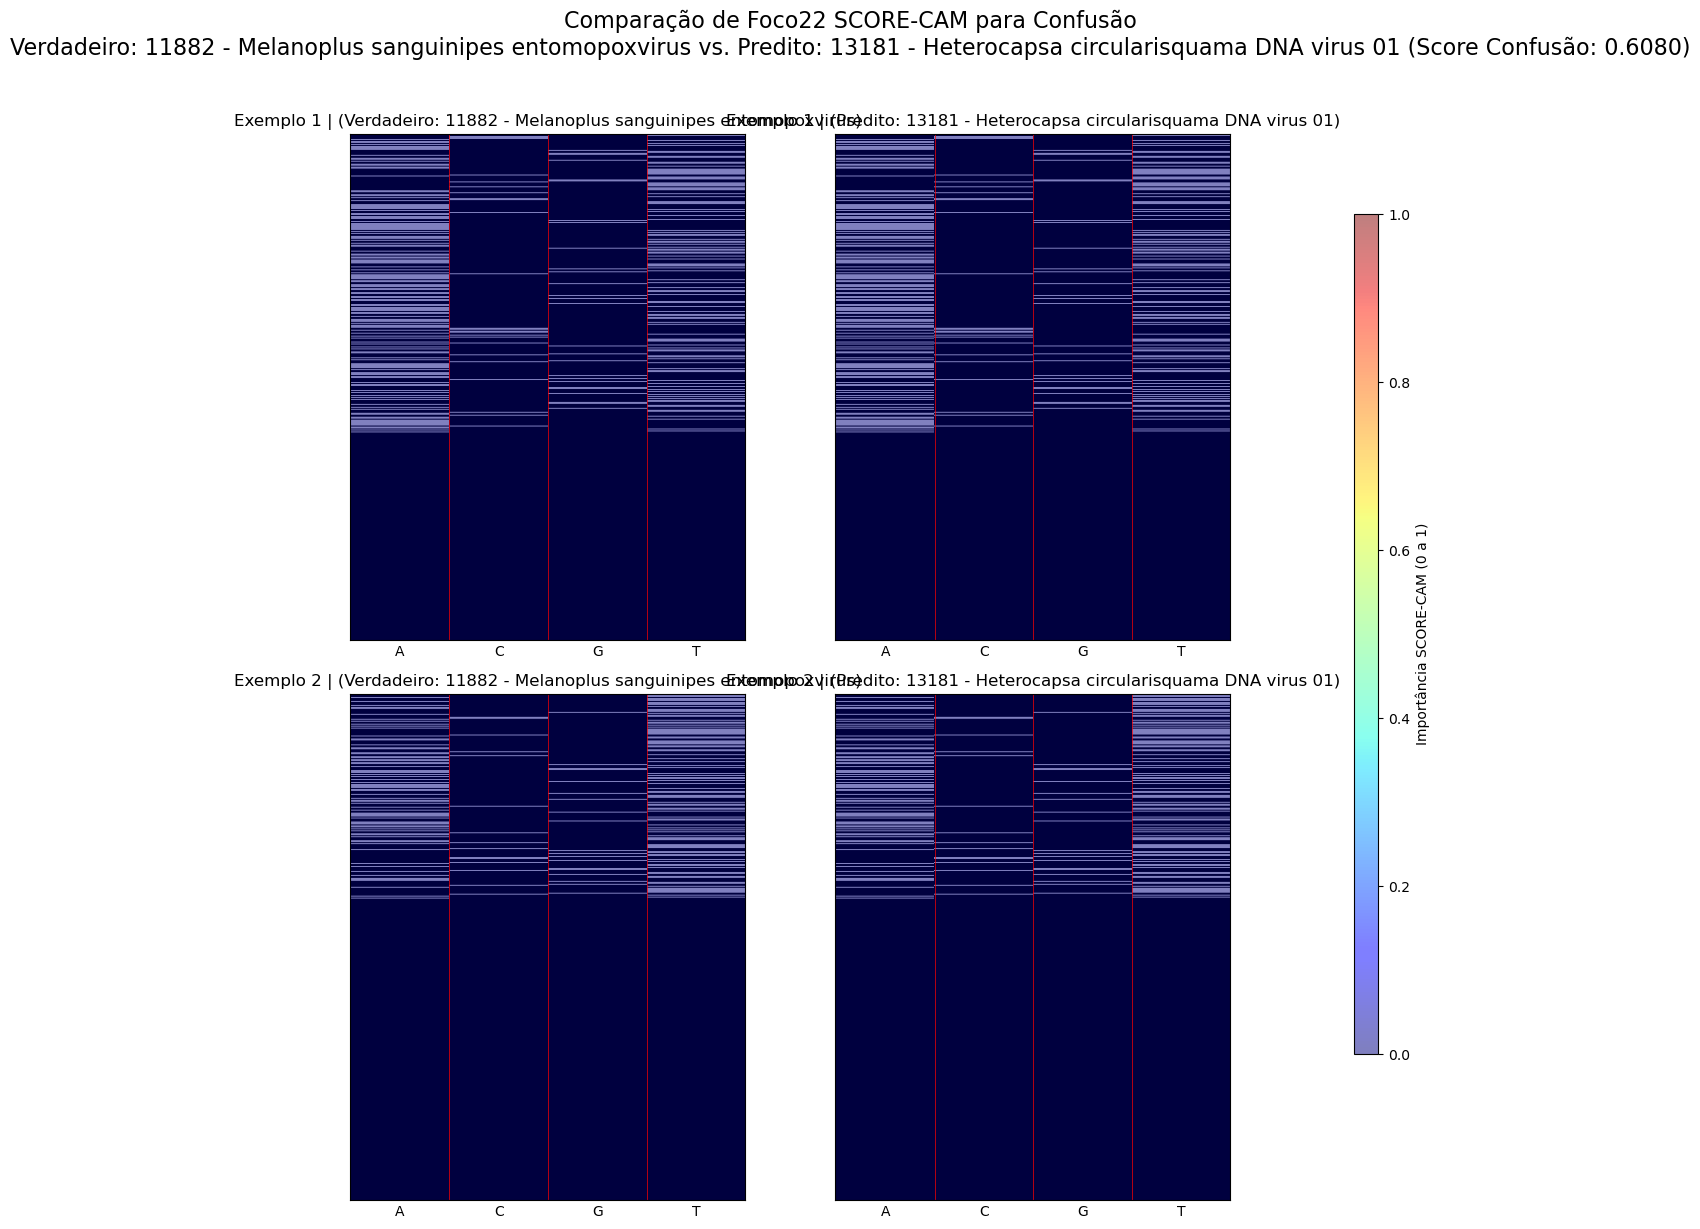


--- Análise de Confusão: Verdadeiro (8532)=8532 - Streptomyces phage Eastland -> Predito (7206)=7206 - Streptomyces phage Piccadilly | Score Confusão: 0.5942 ---


<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


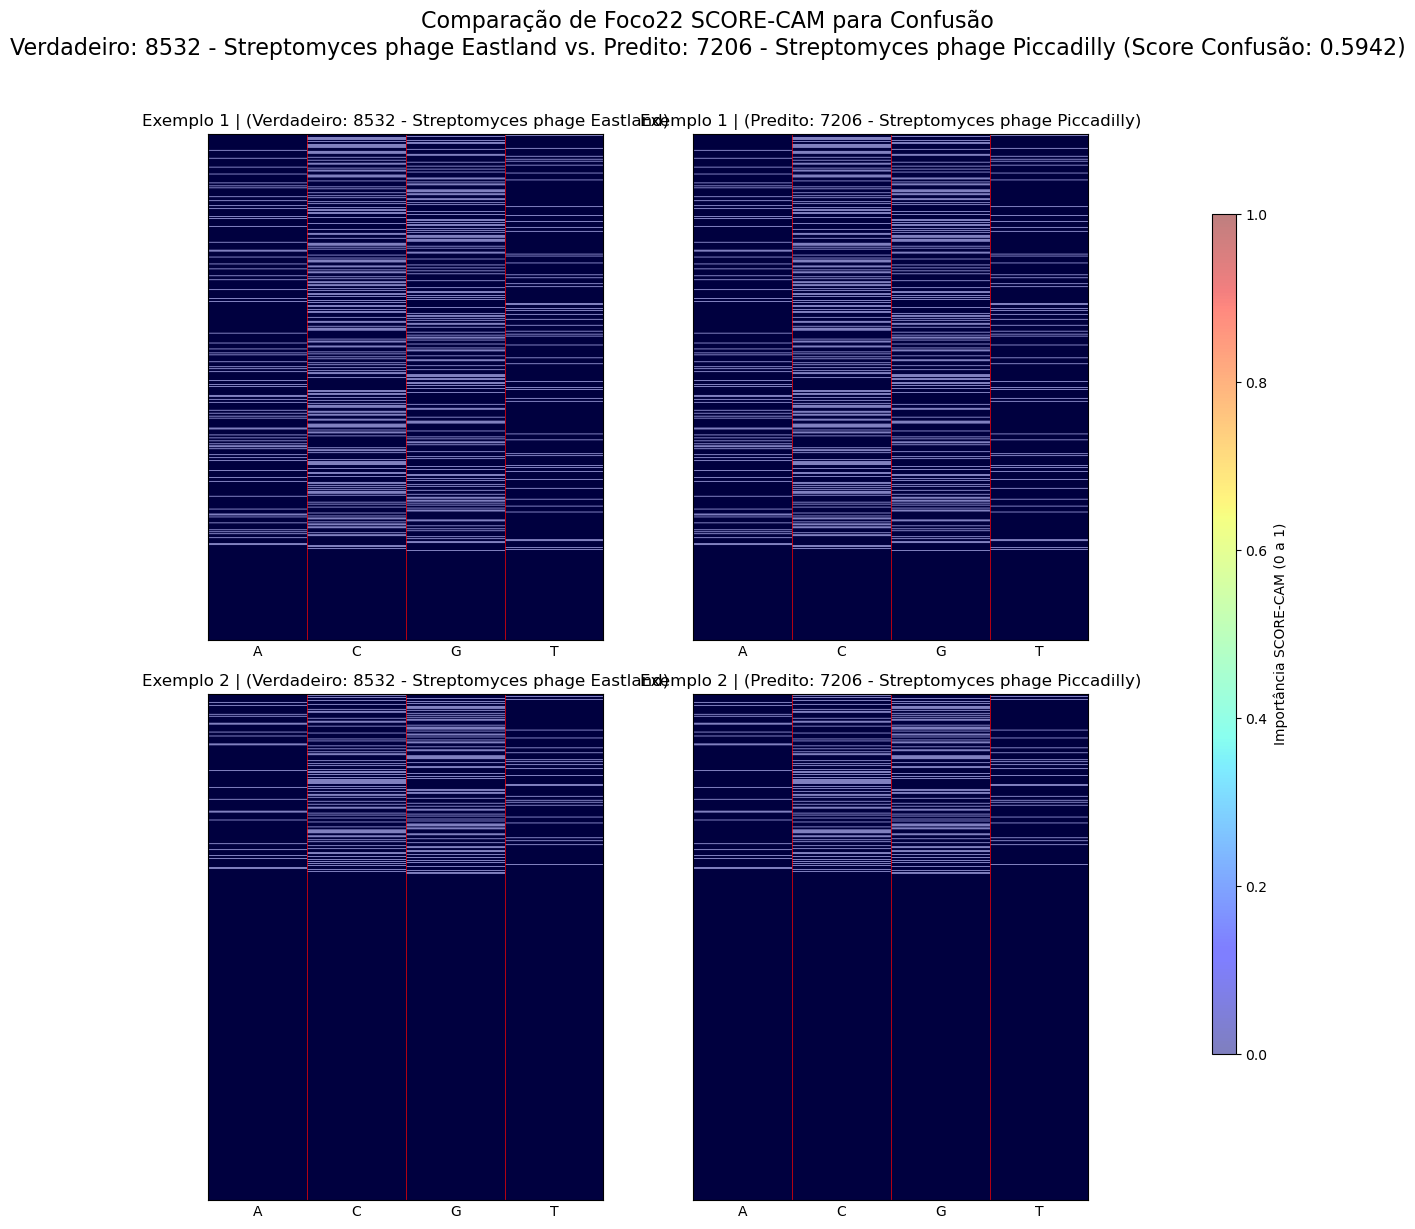


--- Análise de Confusão: Verdadeiro (11888)=11888 - Alphaentomopoxvirus acuprea -> Predito (13181)=13181 - Heterocapsa circularisquama DNA virus 01 | Score Confusão: 0.5455 ---


<string>:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


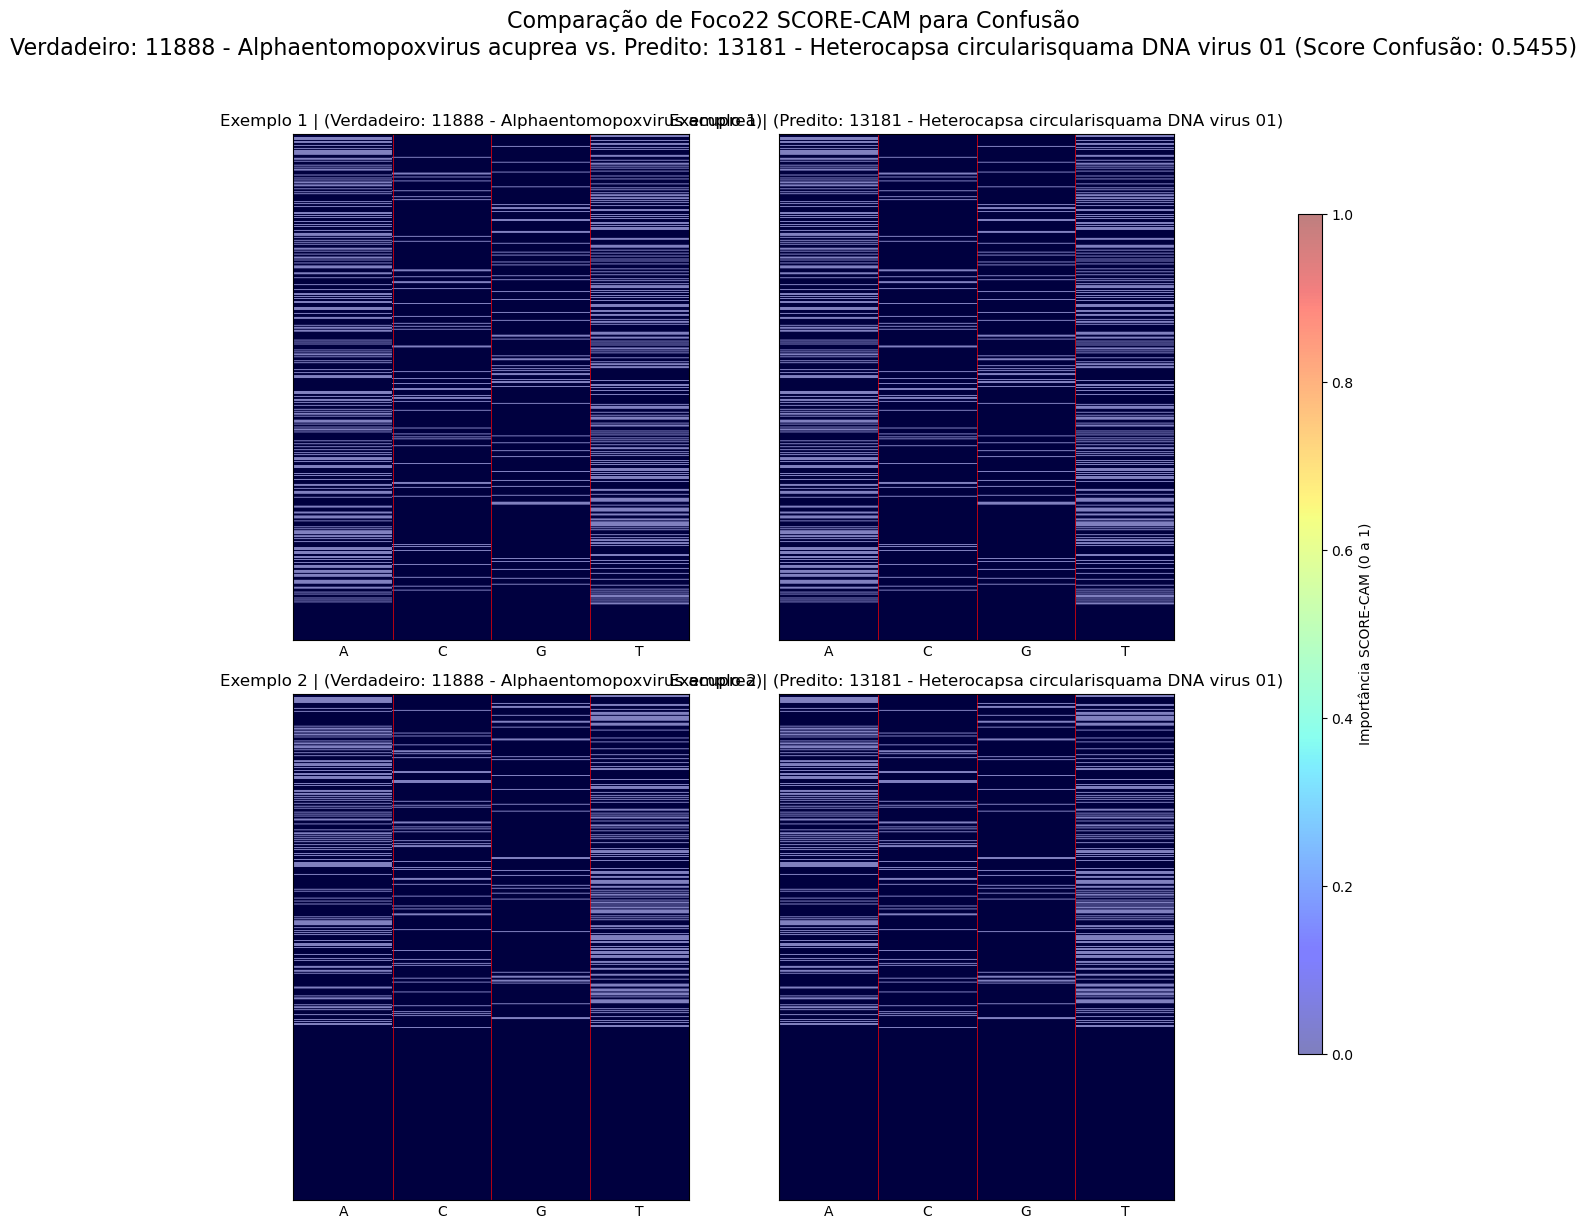

In [61]:
# 1. Tente "desencapsular" o modelo original se ele foi compilado
if hasattr(model, "_orig_mod"):
    print("Revertendo modelo compilado para o original (Eager Mode)...")
    model = model._orig_mod
else:
    print("O modelo atual não parece estar encapsulado pelo torch.compile ou já é o original.")

# 2. Garanta que está em modo de avaliação
model.eval()
target_layer = model.layer4[2].dwconv
for confused_sample in confused_samples:
    #print(confused_sample['class_true']['id'])
    #print(get_class_label(mapping_csv_path = mapping_csv_path, target_label_0based = confused_sample['class_true']['id'],col_name = base_type_data))


    visualize_heat_map_examples_by_class(model, 
                                         target_layer,
                                         confused_sample['class_true']['id'],
                                         confused_sample['class_true']['target_pred_id'],
                                         confused_sample['class_true']['examples'],
                                         confused_sample['score_principal_confusao'],
                                         "SCORE",
                                         DEVICE,
                                         mapping_csv_path = mapping_csv_path_species,
                                         col_name = "species")